# BI10 Round 02 – Challenge 3: Customer Segmentation & Next Best Action

Notebook này trả lời **4 yêu cầu của Challenge 3** và chạy được độc lập từ đầu đến cuối.

| # | Yêu cầu đề bài | Mục trong notebook |
|---|---|---|
| 1 | Combine Financial Health and Engagement | **§2** phân khúc **theo quy tắc** (ma trận ngưỡng FH × ENG) → 7 phân khúc có tên và ý nghĩa; **§2.1** định nghĩa cụ thể + chân dung từng phân khúc |
| 2 | Identify Customer Opportunities | **§3** giá trị giải ngân kỳ vọng và tổn thất kỳ vọng theo phân khúc; **§3.2** cơ hội cụ thể của từng phân khúc (chào ai, chào gì, kênh, thời điểm, giá trị) |
| 3 | Recommend Next Best Action | **§4** bảng quy tắc theo thứ tự ưu tiên: chặn rủi ro → hành động theo phân khúc → điều chỉnh theo hành vi từng khách |
| 4 | Why this action? | **§5** câu giải thích cho từng khách + số liệu bằng chứng cho từng phân khúc; **§6** kế hoạch A/B test |

**Đầu vào**
- `CUSTOMER_clean_labeled`: bảng khách hàng đã gắn nhãn của Challenge 1 (`financial_health_score`, `FH_segment`) và Challenge 2 (`ENG_score`, `ENG_segment`).
- `segment_profile.csv` của Challenge 2: tỉ lệ chuyển đổi 60 ngày đã kiểm chứng out-of-time theo phân khúc ENG.
- Các bảng gốc (CONTRACT, LEADS, PAST_BEHAVIOR, CALL): tính thêm **biến phụ** để chọn hành động (khoản vay đang chạy, ngày kết thúc khoản vay, sản phẩm vừa scoring, cờ quá hạn, cuộc gọi thu nợ).
  Các biến phụ **chỉ dùng trong notebook**, không ghi vào file khách hàng nộp BTC.

**Nguyên tắc**
- Ngưỡng phân khúc **dùng lại** ngưỡng đã kiểm chứng ở Challenge 1 và 2, không đặt thêm ngưỡng mới.
- Rủi ro được kiểm soát bằng **điều kiện chặn**, không bằng một hệ số nhân.
- Không dùng nhân khẩu học (tuổi, giới tính, địa chỉ) trong quy tắc; chỉ dùng để **mô tả** chân dung phân khúc (§2.1).
- Kết quả là liên hệ, không phải nhân quả → mỗi hành động đi kèm **kế hoạch A/B test**.

## 0. Setup & đầu vào

In [1]:
import os
import time
import warnings
from pathlib import Path

import duckdb
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
from scipy.stats import norm

warnings.filterwarnings("ignore", category=FutureWarning)

try:
    from google.colab import drive
    drive.mount("/content/drive")
    DEFAULT_ROOT = "/content/drive/MyDrive/BI10_ROUND02_DATASET"
except ImportError:
    DEFAULT_ROOT = r"C:\BI10_ROUND02_DATASET"
ROOT = Path(os.environ.get("BI10_ROOT", DEFAULT_ROOT))
PQ_DIR = ROOT / "Clean_data" / "parquet"                # parquet cache built by the Challenge 2 notebook
C2_DIR = ROOT / "output" / "challenge2"                 # Challenge 2 outputs
LABEL_FILE = Path(os.environ.get("BI10_LABEL_FILE", C2_DIR / "CUSTOMER_clean_labeled.parquet"))
OUT = ROOT / "output" / "challenge3"
FIG = OUT / "figures"
FIG.mkdir(parents=True, exist_ok=True)

SNAPSHOT = "2025-06-05"   # same scoring date as Challenge 1 and 2 (data ends 2025-06-04)
SEED = 42

pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 220)
pd.set_option("display.float_format", lambda v: f"{v:,.4f}")

BLUE, BLUE_L, ORANGE, GREY, RED, GREEN = "#2a78d6", "#86b6ef", "#eb6834", "#8a8984", "#d03b3b", "#0ca30c"
plt.rcParams.update({
    "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb",
    "axes.edgecolor": "#c3c2b7", "axes.labelcolor": "#52514e", "axes.titlecolor": "#0b0b0b",
    "axes.titlesize": 10, "axes.titleweight": "bold", "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#e6e5e0", "grid.linewidth": 0.6,
    "xtick.color": "#52514e", "ytick.color": "#52514e", "font.size": 8.5,
})
PCT = mtick.PercentFormatter(1, decimals=0)
PCT1 = mtick.PercentFormatter(1, decimals=1)

def save(fig, name):
    fig.tight_layout(rect=(0, 0, 1, 0.97) if fig._suptitle else None)
    fig.savefig(FIG / f"{name}.png", dpi=150, bbox_inches="tight")
    plt.show()

def bar_labels(ax, values, fmt="{:.1%}", horizontal=False, size=7.5):
    for i, v in enumerate(values):
        if pd.isna(v):
            continue
        if horizontal:
            ax.text(v, i, " " + fmt.format(v), va="center", fontsize=size, color="#52514e")
        else:
            ax.text(i, v, fmt.format(v), ha="center", va="bottom", fontsize=size, color="#52514e")

In [2]:
# Typed views on top of the team's Clean_data parquet. Every column is cast defensively, so the
# notebook works whether the parquet came out of Excel as typed columns or as text.
def create_views(con, pq_dir):
    p = lambda name: (pq_dir / f"{name}.parquet").as_posix()
    con.execute("""
        CREATE OR REPLACE MACRO num(x) AS TRY_CAST(CAST(x AS VARCHAR) AS DOUBLE);
        CREATE OR REPLACE MACRO flag(x) AS coalesce(num(x), 0) = 1;
        CREATE OR REPLACE MACRO ts(x) AS coalesce(
            TRY_CAST(CAST(x AS VARCHAR) AS TIMESTAMP),
            TIMESTAMP '1899-12-30' + to_seconds(CAST(num(x) * 86400 AS BIGINT)));   -- Excel serial date fallback
        CREATE OR REPLACE MACRO txt(x) AS NULLIF(NULLIF(trim(CAST(x AS VARCHAR)), ''), 'XNA');
    """)
    con.execute(f"""CREATE OR REPLACE VIEW customer AS
        SELECT CAST(num(SKP_CLIENT) AS BIGINT) AS client,
               coalesce(num(AVG_SESSION_PER_WEEK_2025), 0) AS app_sessions,
               flag(FLAG_GMA_USER) AS app_user
        FROM '{p("CUSTOMER")}'""")
    con.execute(f"""CREATE OR REPLACE VIEW contract AS
        SELECT CAST(num(SKP_CLIENT) AS BIGINT) AS client,
               coalesce(txt(PRODUCT_GROUP), 'UNKNOWN') AS product,
               txt(STATUS_GROUP) AS status_group,
               flag(IS_SIGNED) AS is_signed, flag(IS_REVOLVING) AS is_revolving,
               ts(APPLY_CONTRACT_TIME) AS t_apply,
               coalesce(ts(SIGN_CONTRACT_TIME), ts(APPLY_CONTRACT_TIME)) AS t_sign,
               num(PAYMENT_NUM) AS tenor,
               CASE WHEN num(AMT_CREDIT) > 0 THEN num(AMT_CREDIT) ELSE num(AMT_BILLING) END AS amount
        FROM '{p("CONTRACT")}'""")
    con.execute(f"""CREATE OR REPLACE VIEW leads AS
        SELECT CAST(num(SKP_CLIENT) AS BIGINT) AS client,
               ts(DTIME_CREATED) AS t_created,
               CASE WHEN year(ts(DATE_ACCEPTED)) < 2900 THEN ts(DATE_ACCEPTED) END AS t_accepted,  -- 3000-01-01 = sentinel
               CASE WHEN year(ts(DATE_ACCEPTED)) < 2900 THEN num(ACCEPT_LAG_HOURS) END AS accept_lag_h,
               txt(LEAD_OUTCOME) AS outcome, flag(IS_DEAL) AS is_deal,
               txt(LEAD_SOURCE) AS source, txt(LEAD_SOURCE) IN ('SOB', 'GMA', 'LANDING PAGE') AS is_self,
               txt(PRODUCT_GROUP) AS product
        FROM '{p("LEADS")}'""")
    con.execute(f"""CREATE OR REPLACE VIEW behavior AS
        SELECT CAST(num(SKP_CLIENT) AS BIGINT) AS client, ts(DTIME_EVENT) AS t_event,
               txt(CHANNEL) AS channel, txt(EVENT_TYPE) AS event_type, txt(PRODUCT_GROUP) AS product
        FROM '{p("PAST_BEHAVIOR")}'""")
    con.execute(f"""CREATE OR REPLACE VIEW call AS
        SELECT CAST(num(SKP_CLIENT) AS BIGINT) AS client, ts(TIME_OF_CALL_START) AS t_call,
               txt(CALL_TYPE) = 'Inbound' AS is_inbound, flag(IS_CONNECTED) AS is_connected,
               flag(IS_COLLECTION_CALL) AS is_collection, txt(RESPONSE_GROUP) AS response
        FROM '{p("CALL")}'
        WHERE NOT flag(FLAG_DUP_CALL_ID)""")

In [3]:
CALL_WINDOW_DAYS = 30   # CALL starts 2025-01-01 -> same short window at every as-of date keeps call features comparable

def build_features(con, as_of):
    """All candidate engagement variables measured strictly BEFORE `as_of` (no look-ahead)."""
    a = f"TIMESTAMP '{as_of}'"
    d12, d24 = f"{a} - INTERVAL 365 DAY", f"{a} - INTERVAL 730 DAY"
    d3, d1 = f"{a} - INTERVAL 90 DAY", f"{a} - INTERVAL 30 DAY"
    dc = f"{a} - INTERVAL {CALL_WINDOW_DAYS} DAY"
    days = lambda t: f"date_diff('day', {t}, {a})"
    sql = f"""
    WITH
    beh AS (
        SELECT client,
               {days("max(t_event) FILTER (WHERE event_type = 'SCORING')")} AS rec_scoring_days,
               count(*) FILTER (WHERE event_type = 'SCORING' AND t_event >= {d12}) AS n_scoring_12m,
               count(DISTINCT product) FILTER (WHERE event_type = 'SCORING' AND t_event >= {d12}) AS n_products_scored_12m,
               count(DISTINCT channel) FILTER (WHERE t_event >= {d12}) AS n_channels_12m,
               avg(CASE WHEN channel IN ('APP', 'WEB') THEN 1.0 ELSE 0 END) FILTER (WHERE t_event >= {d12}) AS self_service_share_12m,
               max(t_event) FILTER (WHERE event_type = 'SCORING') AS last_scoring
        FROM behavior WHERE t_event < {a} GROUP BY 1),
    lds AS (
        SELECT client,
               count(*) FILTER (WHERE t_created >= {d12}) AS n_leads_12m,
               count(*) FILTER (WHERE t_created >= {d12} AND t_accepted IS NOT NULL AND t_accepted < {a}) AS n_leads_accepted_12m,
               count(*) FILTER (WHERE t_created >= {d12} AND outcome = 'NOT_INTEREST') AS n_leads_not_interest_12m,
               count(*) FILTER (WHERE t_created >= {d12} AND is_deal) AS n_lead_deals_12m,
               count(*) FILTER (WHERE t_created >= {d12} AND is_self) AS n_self_leads_12m,
               count(*) FILTER (WHERE t_created >= {d12} AND NOT is_self) AS n_company_leads_12m,
               median(accept_lag_h) FILTER (WHERE t_created >= {d12} AND t_accepted < {a}) AS median_accept_lag_h_12m,
               {days('max(t_created)')} AS rec_lead_days,
               max(t_created) FILTER (WHERE is_self) AS last_self_lead
        FROM leads WHERE t_created < {a} GROUP BY 1),
    cl AS (
        SELECT client,
               count(*) FILTER (WHERE NOT is_inbound) AS n_sales_calls_30d,
               avg(is_connected::INT) FILTER (WHERE NOT is_inbound) AS call_answer_rate_30d,
               count(*) FILTER (WHERE is_inbound) AS n_inbound_calls_30d,
               count(*) FILTER (WHERE is_connected AND response = 'REFUSE') AS n_call_refuse_30d,
               count(*) FILTER (WHERE response = 'TERMINATION_REQUEST') AS n_termination_req_30d
        FROM call WHERE NOT is_collection AND t_call >= {dc} AND t_call < {a} GROUP BY 1),
    ct AS (   -- contracts known at as_of (applied before it)
        SELECT * REPLACE (is_signed AND t_sign < {a} AS is_signed),   -- a loan counts as booked only once signed before as_of
               t_sign + to_months(CAST(coalesce(tenor, 0) AS INT)) AS t_end
        FROM contract WHERE t_apply < {a}),
    apps AS (
        SELECT client,
               {days('max(t_sign) FILTER (WHERE is_signed)')} AS rec_booking_days,
               count(*) FILTER (WHERE is_signed AND t_apply >= {d24}) AS n_signed_24m,
               count(DISTINCT product) FILTER (WHERE is_signed AND product <> 'UNKNOWN') AS n_products_held,
               max(CASE WHEN is_signed AND is_revolving THEN 1 ELSE 0 END) AS has_revolving,
               count(*) FILTER (WHERE is_signed AND (is_revolving OR t_end >= {a})) AS n_running,
               count(*) FILTER (WHERE t_apply >= {d24}) AS n_apps_24m,
               avg(CASE WHEN status_group = 'CANCELLED' THEN 1.0 ELSE 0 END) FILTER (WHERE t_apply >= {d24}) AS cancel_rate_24m,
               avg(CASE WHEN status_group = 'REJECTED' THEN 1.0 ELSE 0 END) FILTER (WHERE t_apply >= {d24}) AS reject_rate_24m
        FROM ct GROUP BY 1),
    gaps AS (   -- median days between consecutive applications (application rhythm)
        SELECT client, median(gap) AS median_app_gap_days
        FROM (SELECT client, date_diff('day', lag(t_apply) OVER (PARTITION BY client ORDER BY t_apply), t_apply) AS gap FROM ct)
        WHERE gap IS NOT NULL GROUP BY 1),
    rep AS (   -- repeat rate: share of loans that ended before as_of and were followed by a new application
        SELECT e.client, avg(CASE WHEN EXISTS (SELECT 1 FROM ct n WHERE n.client = e.client AND n.t_apply > e.t_end) THEN 1.0 ELSE 0 END) AS repeat_rate
        FROM ct e WHERE e.is_signed AND NOT e.is_revolving AND e.tenor > 0 AND e.t_end < {a} GROUP BY 1),
    acts AS (     -- customer-initiated actions only: scoring, self-created leads, applications (not company steps)
        SELECT client, t_event AS t FROM behavior WHERE t_event >= {d12} AND t_event < {a}
        UNION ALL SELECT client, t_created FROM leads WHERE is_self AND t_created >= {d12} AND t_created < {a}
        UNION ALL SELECT client, t_apply FROM contract WHERE t_apply >= {d12} AND t_apply < {a}),
    months AS (
        SELECT client, count(DISTINCT date_trunc('month', t)) AS active_months_12m,
               avg(CASE WHEN t >= {d3} THEN 1.0 ELSE 0 END) AS recent_activity_share
        FROM acts GROUP BY 1),
    fun AS (      -- personal funnel: share of scoring events followed by an application within 30 days
        SELECT s.client, avg(CASE WHEN p.t_apply <= s.t_event + INTERVAL 30 DAY THEN 1.0 ELSE 0 END) AS scoring_to_app_rate_12m
        FROM (SELECT client, t_event FROM behavior WHERE event_type = 'SCORING' AND t_event >= {d12} AND t_event < {d1}) s
        ASOF LEFT JOIN (SELECT client, t_apply FROM contract WHERE t_apply < {a}) p
            ON s.client = p.client AND p.t_apply >= s.t_event
        GROUP BY 1)
    SELECT c.client, c.app_sessions, c.app_user,
           {days('greatest(b.last_scoring, l.last_self_lead)')} AS rec_touch_days,
           b.rec_scoring_days, a.rec_booking_days, l.rec_lead_days,
           coalesce(m.active_months_12m, 0) AS active_months_12m, m.recent_activity_share,
           coalesce(b.n_scoring_12m, 0) AS n_scoring_12m,
           coalesce(a.n_signed_24m, 0) AS n_signed_24m,
           coalesce(k.n_sales_calls_30d, 0) AS n_sales_calls_30d, k.call_answer_rate_30d,
           coalesce(k.n_inbound_calls_30d, 0) AS n_inbound_calls_30d,
           coalesce(k.n_call_refuse_30d, 0) AS n_call_refuse_30d,
           coalesce(k.n_termination_req_30d, 0) AS n_termination_req_30d,
           coalesce(b.n_channels_12m, 0) AS n_channels_12m, b.self_service_share_12m,
           coalesce(l.n_leads_12m, 0) AS n_leads_12m,
           l.n_leads_accepted_12m / nullif(l.n_leads_12m, 0) AS lead_accept_rate_12m,
           l.n_leads_not_interest_12m / nullif(l.n_leads_12m, 0) AS lead_not_interest_rate_12m,
           coalesce(l.n_lead_deals_12m, 0) AS n_lead_deals_12m,
           coalesce(l.n_self_leads_12m, 0) AS n_self_leads_12m,
           coalesce(l.n_company_leads_12m, 0) AS n_company_leads_12m,
           l.median_accept_lag_h_12m, f.scoring_to_app_rate_12m,
           coalesce(b.n_products_scored_12m, 0) AS n_products_scored_12m,
           coalesce(a.n_products_held, 0) AS n_products_held,
           coalesce(a.has_revolving, 0) AS has_revolving,
           coalesce(a.n_running, 0) AS n_running,
           r.repeat_rate,
           coalesce(a.n_apps_24m, 0) AS n_apps_24m, a.cancel_rate_24m, a.reject_rate_24m,
           g.median_app_gap_days
    FROM customer c
    LEFT JOIN beh b USING (client) LEFT JOIN lds l USING (client) LEFT JOIN cl k USING (client)
    LEFT JOIN apps a USING (client) LEFT JOIN gaps g USING (client) LEFT JOIN rep r USING (client)
    LEFT JOIN months m USING (client) LEFT JOIN fun f USING (client)
    ORDER BY c.client"""
    df = con.execute(sql).df()
    for col in df.columns:
        if col != "client":
            df[col] = pd.to_numeric(df[col], errors="coerce").astype("float64")
    return df


def build_outcomes(con, as_of, end):
    """Business outcomes in the window [as_of, end): conversion = new signed loan applied in the window or a lead deal."""
    a, e = f"TIMESTAMP '{as_of}'", f"TIMESTAMP '{end}'"
    return con.execute(f"""
    WITH k AS (SELECT client, count(*) AS new_apps, count(*) FILTER (WHERE is_signed) AS new_booked,
                      sum(amount) FILTER (WHERE is_signed) AS new_booked_amount
               FROM contract WHERE t_apply >= {a} AND t_apply < {e} GROUP BY 1),
         d AS (SELECT client, count(*) AS new_lead_deals FROM leads WHERE is_deal AND t_created >= {a} AND t_created < {e} GROUP BY 1)
    SELECT c.client,
           CASE WHEN coalesce(k.new_booked, 0) + coalesce(d.new_lead_deals, 0) > 0 THEN 1 ELSE 0 END AS converted,
           CASE WHEN coalesce(k.new_apps, 0) > 0 THEN 1 ELSE 0 END AS applied,
           coalesce(k.new_booked_amount, 0) AS new_booked_amount
    FROM customer c LEFT JOIN k USING (client) LEFT JOIN d USING (client) ORDER BY c.client""").df()

In [4]:
con = duckdb.connect()
create_views(con, PQ_DIR)
q = lambda sql: con.execute(sql).df()

lab = pd.read_parquet(LABEL_FILE) if LABEL_FILE.suffix == ".parquet" else pd.read_csv(LABEL_FILE)
lab = lab[["SKP_CLIENT", "financial_health_score", "FH_segment", "ENG_score", "ENG_segment"]].rename(
    columns={"financial_health_score": "FH_score"})
lab["SKP_CLIENT"] = lab["SKP_CLIENT"].astype("int64")
prof = pd.read_csv(C2_DIR / "segment_profile.csv", index_col=0)
P_CONV = prof["conv 60d at T1 (holdout, out-of-time)"]          # 60-day conversion, validated out-of-time in Challenge 2
print(f"labels: {len(lab):,} customers | missing labels: {lab.isna().sum().sum()}")
print("ENG conversion used for opportunity sizing:", P_CONV.round(4).to_dict())
lab.head()

labels: 1,000,528 customers | missing labels: 0
ENG conversion used for opportunity sizing: {'Champions': 0.1444, 'Active': 0.0879, 'Warm': 0.0481, 'Dormant': 0.0228}


,SKP_CLIENT,FH_score,FH_segment,ENG_score,ENG_segment
0,676,58.2000,B · Khỏe,90.5000,Champions
1,1470,79.1000,A · Rất khỏe,46.6000,Warm
2,7123,23.9000,E · Rủi ro cao,24.8000,Dormant
3,10711,58.5000,B · Khỏe,24.8000,Dormant
4,12407,20.1000,E · Rủi ro cao,51.2000,Warm


### 0.1 Biến phụ để chọn hành động (chỉ dùng trong notebook)
| Biến | Dùng để | Nguồn |
|---|---|---|
| `active_overdue`, `bad_debt`, `collection_90d` | **Điều kiện chặn**: đang có khoản vay từng quá hạn còn chạy, có nợ xấu, hoặc bị gọi thu nợ trong 90 ngày trước ngày chốt | CONTRACT, CALL |
| `never_booked`, `not_yet_due`, `few_installments` | **Mô tả thành phần** nhóm *Chưa đủ lịch sử trả nợ* (FH = N): chưa từng vay · có khoản vay chưa đến kỳ trả đầu tiên (ngày ký + 1 tháng > ngày chốt) · khoản vay mới qua 1–2 kỳ. Tính trên **mọi sản phẩm, kể cả BNPL và thẻ** | CONTRACT |
| `days_since_booking` | **Hoãn** nếu vừa giải ngân dưới 60 ngày (Challenge 2: khách vừa vay xong ít quay lại) | CONTRACT |
| `days_to_loan_end`, `days_since_loan_end` | **Chào vay tiếp** khi khoản vay sắp hoặc vừa kết thúc (Challenge 2: có khoản vay đã kết thúc ×2,07) | CONTRACT (ngày ký + số kỳ) |
| `last_scored_product`, `last_lead_product`, `held_*` | **Chọn sản phẩm**: chào đúng sản phẩm khách vừa tìm hiểu, hoặc sản phẩm chưa có | PAST_BEHAVIOR, LEADS, CONTRACT |
| `ticket` | **Số tiền kỳ vọng**: số tiền thực giải ngân năm 2025 theo sản phẩm (không dùng hạn mức offer vì cao hơn nhiều so với số tiền thực vay) | CONTRACT |

> Lưu ý dữ liệu: CONTRACT chỉ có cờ quá hạn ở **4 kỳ đầu**, không có trạng thái nợ hiện tại. Vì vậy "đang quá hạn" được xấp xỉ bằng *khoản vay **đang chạy** đã từng quá hạn*.

In [5]:
a = f"TIMESTAMP '{SNAPSHOT}'"
OFFER_PRODUCTS = ["CL", "CC", "BNPL", "CD", "TW"]
con.execute(f"""CREATE OR REPLACE VIEW contract_risk AS
    SELECT CAST(num(SKP_CLIENT) AS BIGINT) AS client, txt(STATUS_GROUP) AS status_group, flag(IS_SIGNED) AS is_signed,
           flag(FLAG_EVER_OVERDUE) AS ever_overdue, coalesce(txt(PRODUCT_GROUP), 'UNKNOWN') AS product,
           ts(APPLY_CONTRACT_TIME) AS t_apply
    FROM '{(PQ_DIR / "CONTRACT.parquet").as_posix()}'""")
NF = q(f"""
WITH ct AS (
    SELECT client, product, is_revolving, amount, tenor, t_sign, t_sign + to_months(CAST(coalesce(tenor, 0) AS INT)) AS t_end
    FROM contract WHERE is_signed AND t_sign < {a}),
loan AS (
    SELECT client,
           date_diff('day', max(t_sign), {a}) AS days_since_booking,
           min(date_diff('day', {a}, t_end)) FILTER (WHERE NOT is_revolving AND t_end >= {a}) AS days_to_loan_end,
           min(date_diff('day', t_end, {a})) FILTER (WHERE NOT is_revolving AND t_end < {a}) AS days_since_loan_end,
           count(*) FILTER (WHERE is_revolving OR t_end >= {a}) AS n_running,
           max(least(coalesce(tenor, 99), date_diff('month', t_sign, {a}))) AS n_inst_elapsed,   -- instalments passed, any product
           {", ".join(f"max(CASE WHEN product = '{p}' THEN 1 ELSE 0 END) AS held_{p}" for p in OFFER_PRODUCTS)},
           {", ".join(f"arg_max(amount, t_sign) FILTER (WHERE product = '{p}') AS last_amt_{p}" for p in OFFER_PRODUCTS)}
    FROM ct GROUP BY 1),
risk AS (
    SELECT client,
           max(CASE WHEN is_signed AND ever_overdue THEN 1 ELSE 0 END) AS ever_overdue,
           max(CASE WHEN is_signed AND ever_overdue AND status_group = 'ACTIVE' THEN 1 ELSE 0 END) AS active_overdue,
           max(CASE WHEN status_group = 'BAD_DEBT' THEN 1 ELSE 0 END) AS bad_debt,
           max(CASE WHEN is_signed THEN 1 ELSE 0 END) AS booked_any
    FROM contract_risk WHERE t_apply < {a} GROUP BY 1),
coll AS (
    SELECT client, 1 AS collection_90d FROM call
    WHERE is_collection AND t_call >= {a} - INTERVAL 90 DAY AND t_call < {a} GROUP BY 1),
sc AS (
    SELECT client, arg_max(product, t_event) AS last_scored_product, date_diff('day', max(t_event), {a}) AS days_since_scoring
    FROM behavior WHERE event_type = 'SCORING' AND t_event < {a} AND product IN ({", ".join(f"'{p}'" for p in OFFER_PRODUCTS)}) GROUP BY 1),
ld AS (
    SELECT client, arg_max(product, t_created) AS last_lead_product, date_diff('day', max(t_created), {a}) AS days_since_lead
    FROM leads WHERE t_created < {a} AND product IN ({", ".join(f"'{p}'" for p in OFFER_PRODUCTS)}) GROUP BY 1)
SELECT c.client AS SKP_CLIENT, l.* EXCLUDE (client), r.* EXCLUDE (client),
       coalesce(k.collection_90d, 0) AS collection_90d, s.* EXCLUDE (client), d.* EXCLUDE (client)
FROM customer c LEFT JOIN loan l USING (client) LEFT JOIN risk r USING (client) LEFT JOIN coll k USING (client)
LEFT JOIN sc s USING (client) LEFT JOIN ld d USING (client) ORDER BY 1""")
for c in ["n_running", "ever_overdue", "active_overdue", "bad_debt", "booked_any", "collection_90d"] + [f"held_{p}" for p in OFFER_PRODUCTS]:
    NF[c] = NF[c].fillna(0).astype(int)
for c in ["days_since_booking", "days_to_loan_end", "days_since_loan_end", "days_since_scoring", "days_since_lead", "n_inst_elapsed"] \
         + [f"last_amt_{p}" for p in OFFER_PRODUCTS]:
    NF[c] = pd.to_numeric(NF[c], errors="coerce").astype("float64")   # nullable ints -> float so comparisons give plain booleans
NF["never_booked"] = 1 - NF["booked_any"]
NF["not_yet_due"] = ((NF["booked_any"] == 1) & (NF["n_inst_elapsed"] == 0)).astype(int)        # 1st due = sign + 1 month > snapshot
NF["few_installments"] = ((NF["booked_any"] == 1) & NF["n_inst_elapsed"].between(1, 2)).astype(int)

# Typical loan amount per product = median of loans actually disbursed in 2025 (BNPL uses the billed amount)
TICKET = q(f"""SELECT product, MEDIAN(amount) AS median_amount, QUANTILE_CONT(amount, 0.9) AS p90_amount, COUNT(*) AS loans
               FROM contract WHERE is_signed AND t_sign >= TIMESTAMP '2025-01-01' AND t_sign < {a} AND amount > 0
               AND product IN ({", ".join(f"'{p}'" for p in OFFER_PRODUCTS)}) GROUP BY 1""").set_index("product")
df = lab.merge(NF, on="SKP_CLIENT", how="left", validate="one_to_one")
assert len(df) == len(lab)
print(f"helper variables for {len(df):,} customers")
display(TICKET)
df[["active_overdue", "bad_debt", "collection_90d", "never_booked", "n_running"]].agg(["mean", "sum"]).T

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

helper variables for 1,000,528 customers


,median_amount,p90_amount,loans
product,,,
TW,"24,800,000.0000","40,865,000.0000",21471
CL,"25,000,000.0000","75,000,000.0000",72837
BNPL,"617,500.0000","2,900,000.0000",65095
CC,"25,000,000.0000","46,000,000.0000",20348
CD,"7,090,000.0000","14,690,000.0000",333151


,mean,sum
active_overdue,0.0159,"15,861.0000"
bad_debt,0.0137,"13,664.0000"
collection_90d,0.0149,"14,934.0000"
never_booked,0.1823,"182,420.0000"
n_running,0.9077,"908,152.0000"


---
## 1. Hai điểm đầu vào có bổ sung cho nhau không?
Nếu FH và ENG trùng nhau thì ghép hai trục không thêm thông tin. Kiểm tra tương quan và phân bố chéo.

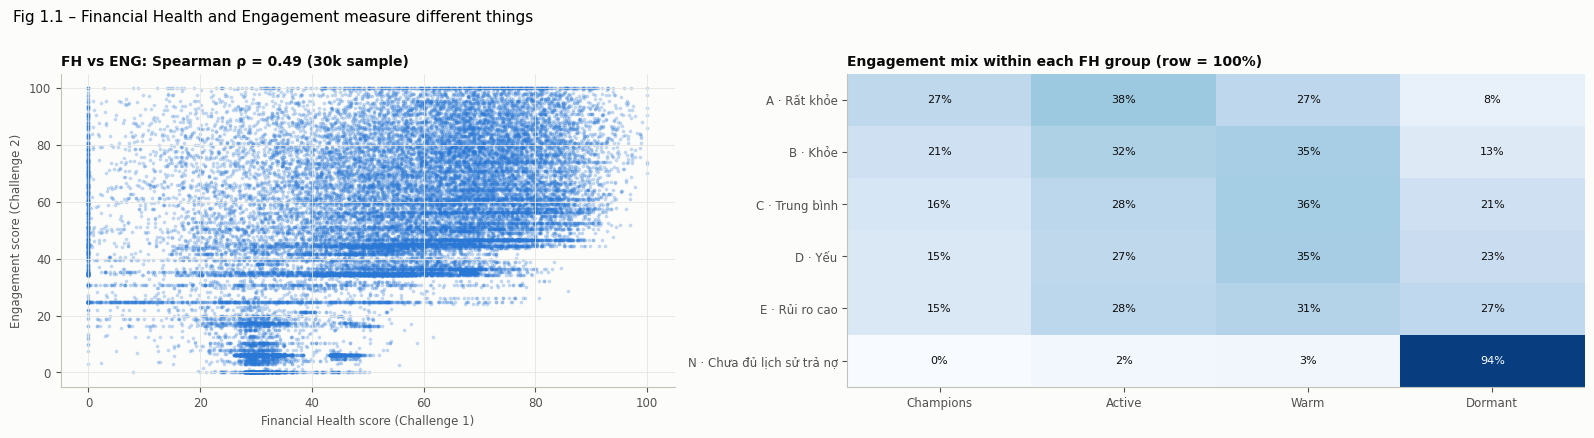

In [6]:
rho = df[["FH_score", "ENG_score"]].corr("spearman").iat[0, 1]
FH_ORDER = sorted(df["FH_segment"].unique(), key=lambda s: "ABCDEN".find(s[0]) if s[0] in "ABCDEN" else 9)
ENG_ORDER = ["Champions", "Active", "Warm", "Dormant"]
ct = pd.crosstab(df["FH_segment"], df["ENG_segment"], normalize="index").reindex(index=FH_ORDER, columns=ENG_ORDER)

fig, axes = plt.subplots(1, 2, figsize=(16, 4.4), gridspec_kw={"width_ratios": [1, 1.2]})
ax = axes[0]
smp = df.sample(30_000, random_state=SEED)
ax.scatter(smp["FH_score"], smp["ENG_score"], s=3, alpha=0.2, color=BLUE)
ax.set_xlabel("Financial Health score (Challenge 1)"); ax.set_ylabel("Engagement score (Challenge 2)")
ax.set_title(f"FH vs ENG: Spearman ρ = {rho:.2f} (30k sample)", loc="left")
ax = axes[1]
im = ax.imshow(ct.values, cmap="Blues", vmin=0, vmax=1, aspect="auto")
ax.set_xticks(range(4), ENG_ORDER); ax.set_yticks(range(len(FH_ORDER)), FH_ORDER); ax.grid(False)
for i in range(ct.shape[0]):
    for j in range(ct.shape[1]):
        ax.text(j, i, f"{ct.iat[i, j]:.0%}", ha="center", va="center", fontsize=8, color="white" if ct.iat[i, j] > 0.5 else "#0b0b0b")
ax.set_title("Engagement mix within each FH group (row = 100%)", loc="left")
fig.suptitle("Fig 1.1 – Financial Health and Engagement measure different things", x=0.01, ha="left", fontsize=11)
save(fig, "1_1_fh_vs_eng")

> **💡 Insight (Fig 1.1):**
> - FH và ENG **tương quan vừa phải** (Spearman ρ = 0,49): khách khỏe hơn thường gắn kết hơn, nhưng hai điểm **không trùng nhau**.
> - Trong nhóm FH A (rất khỏe) vẫn có **35%** khách gắn kết thấp (Warm + Dormant). Trong nhóm FH E (rủi ro cao) lại có **43%** khách gắn kết cao (Champions + Active).
> - Nhóm *Chưa đủ lịch sử trả nợ* (N) có 94% khách ở mức Dormant.
>
> **➡️ Ý nghĩa:** Hai trục **bổ sung cho nhau**. FH cho biết *có nên* cho vay, ENG cho biết *khách có muốn* vay, và nên chào *lúc nào, qua kênh nào*. Ghép hai trục tách được những nhóm mà một điểm đơn lẻ bỏ sót: *khỏe nhưng đang nguội* (Sleeping Gems) và *yếu nhưng vẫn muốn vay* (Stressed Seekers).

---
## 2. Ghép FH × ENG thành phân khúc (Yêu cầu 1)

**Phương pháp phân khúc: theo quy tắc (rule-based), không dùng phân cụm.**
Mỗi khách được xếp vào phân khúc bằng **ngưỡng cố định** trên hai điểm đã kiểm chứng (FH × ENG). Khách chưa đủ lịch sử trả nợ (FH = N) là một phân khúc riêng.

Lý do chọn quy tắc thay vì phân cụm (k-means…):
1. **Giải thích được**: mỗi phân khúc có định nghĩa một câu, ví dụ "FH cao và ENG thấp". Cụm từ k-means thì phải đặt tên sau, và ranh giới không rõ.
2. **Ngưỡng đã được kiểm chứng**: ngưỡng FH đến từ Challenge 1, ngưỡng ENG được cắt theo lift chuyển đổi ở Challenge 2. Không thêm tham số mới (số cụm, khởi tạo…).
3. **Ổn định**: cùng một khách luôn vào cùng một phân khúc. Phân cụm có thể đổi kết quả khi dữ liệu thay đổi.
4. **Gắn trực tiếp với hành động**: mỗi ô ma trận tương ứng một nhóm hành động NBA, đúng yêu cầu của đề là đề xuất phải thực thi được.

**Ngưỡng dùng lại từ hai challenge trước:**
- FH (Challenge 1): **Cao** = A + B (≥ 58 điểm) · **Trung bình** = C + D (40–58) · **Thấp** = E (< 40) · **Chưa đủ lịch sử trả nợ** = N (chưa có khoản vay nào, kể cả BNPL và thẻ, qua ≥ 3 kỳ trả).
- ENG (Challenge 2): **Cao** = Champions + Active (≥ 56,8 điểm) · **Thấp** = Warm + Dormant.

Khách **chưa đủ lịch sử trả nợ** (FH = N: chưa có khoản vay nào, kể cả BNPL và thẻ, qua ≥ 3 kỳ trả) là **một phân khúc duy nhất**, vì logic nhất quán: *thiếu bằng chứng trả nợ thì chưa xếp vào nhóm khỏe*, dù khách chưa từng vay hay vừa mới vay. Cờ ẩn `not_yet_due` / `few_installments` chỉ dùng để mô tả thành phần của nhóm.

| Phân khúc | FH | ENG | Ý nghĩa |
|---|---|---|---|
| ⭐ **Stars** | Cao | Cao | Khỏe và đang tích cực: cơ hội lớn nhất |
| 💎 **Sleeping Gems** | Cao | Thấp | Khỏe nhưng đang nguội: cần kích hoạt lại |
| 🌱 **Growth** | Trung bình | Cao | Có nhu cầu, rủi ro vừa: phát triển có kiểm soát |
| ❄️ **Cool Prospects** | Trung bình | Thấp | Ít nhu cầu, rủi ro vừa: nuôi dưỡng chi phí thấp |
| ⚠️ **Stressed Seekers** | Thấp | Cao | Vẫn muốn vay dù tài chính yếu: **không** cấp thêm |
| 🛑 **At-Risk Dormant** | Thấp | Thấp | Yếu và không tương tác: bảo vệ danh mục |
| 🌱 **Insufficient History** | Chưa đủ lịch sử trả nợ (N) | (mọi mức) | Hạn mức nhỏ (BNPL/CD), tăng dần sau mỗi kỳ trả đúng hạn: vừa là sản phẩm, vừa là công cụ tích lũy lịch sử trả nợ |

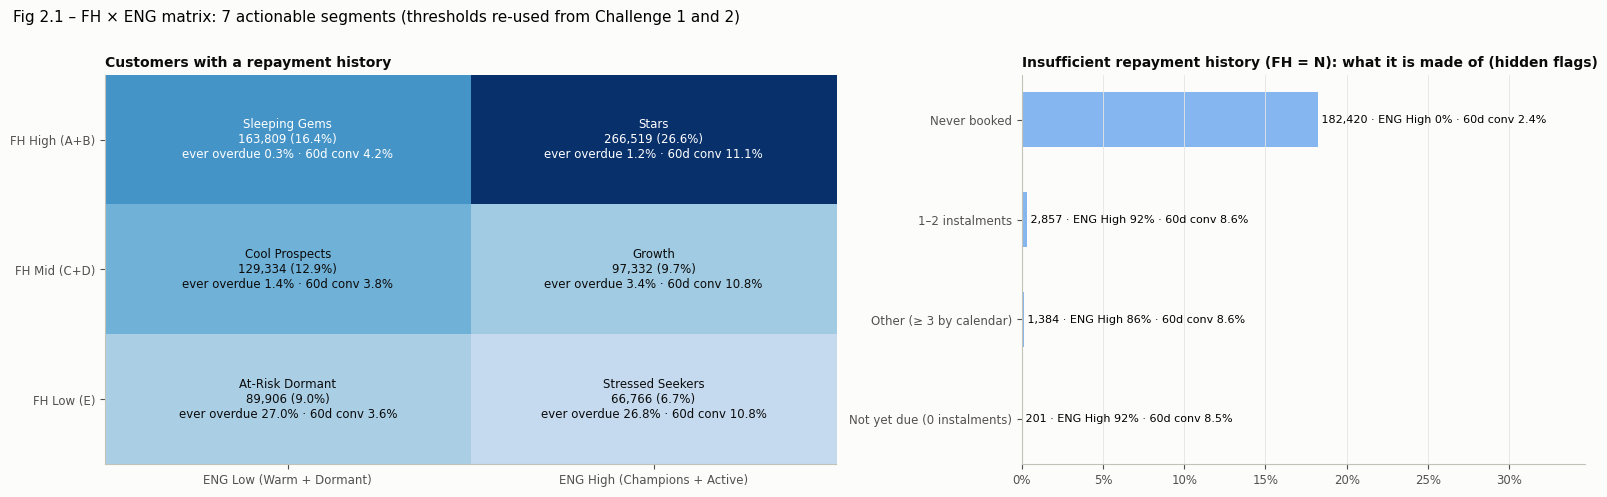

,customers,share
Segment,,
Stars,266519,0.2664
Sleeping Gems,163809,0.1637
Growth,97332,0.0973
Cool Prospects,129334,0.1293
Stressed Seekers,66766,0.0667
At-Risk Dormant,89906,0.0899
Insufficient History,186862,0.1868


In [7]:
FH_TIER = {"A": "High", "B": "High", "C": "Mid", "D": "Mid", "E": "Low", "N": "Thin",
           "Excellent": "High", "Good": "High", "Fair": "Mid", "Watch": "Mid", "Distressed": "Low", "No credit history": "Thin"}
df["FH_tier"] = df["FH_segment"].map(lambda s: FH_TIER.get(s, FH_TIER.get(str(s)[0], "Thin")))
df["ENG_tier"] = np.where(df["ENG_segment"].isin(["Champions", "Active"]), "High", "Low")
SEG_MAP = {("High", "High"): "Stars", ("High", "Low"): "Sleeping Gems", ("Mid", "High"): "Growth", ("Mid", "Low"): "Cool Prospects",
           ("Low", "High"): "Stressed Seekers", ("Low", "Low"): "At-Risk Dormant"}
df["Segment"] = [SEG_MAP.get((f, e)) for f, e in zip(df["FH_tier"], df["ENG_tier"])]
thin = df["FH_tier"] == "Thin"
df["thin_reason"] = np.select([df["never_booked"] == 1, df["not_yet_due"] == 1, df["few_installments"] == 1],
                              ["Never booked", "Not yet due (0 instalments)", "1–2 instalments"], default="Other (≥ 3 by calendar)")
df.loc[thin, "Segment"] = "Insufficient History"
SEG_ORDER = ["Stars", "Sleeping Gems", "Growth", "Cool Prospects", "Stressed Seekers", "At-Risk Dormant", "Insufficient History"]
assert df["Segment"].notna().all()

counts = pd.crosstab(df["FH_tier"], df["ENG_tier"]).reindex(index=["High", "Mid", "Low"], columns=["Low", "High"])
od = df.groupby(["FH_tier", "ENG_tier"])["ever_overdue"].mean().unstack().reindex(index=["High", "Mid", "Low"], columns=["Low", "High"])
pc = df.assign(p=df["ENG_segment"].map(P_CONV)).groupby(["FH_tier", "ENG_tier"])["p"].mean().unstack().reindex(index=["High", "Mid", "Low"], columns=["Low", "High"])

fig, axes = plt.subplots(1, 2, figsize=(16, 5), gridspec_kw={"width_ratios": [1.3, 1]})
ax = axes[0]
share = counts / len(df)
ax.imshow(share.values, cmap="Blues", vmin=0, aspect="auto")
ax.set_xticks(range(2), ["ENG Low (Warm + Dormant)", "ENG High (Champions + Active)"])
ax.set_yticks(range(3), ["FH High (A+B)", "FH Mid (C+D)", "FH Low (E)"]); ax.grid(False)
for i, f in enumerate(["High", "Mid", "Low"]):
    for j, e in enumerate(["Low", "High"]):
        v = share.iat[i, j]
        ax.text(j, i, f"{SEG_MAP[(f, e)]}\n{counts.iat[i, j]:,} ({v:.1%})\never overdue {od.iat[i, j]:.1%} · 60d conv {pc.iat[i, j]:.1%}",
                ha="center", va="center", fontsize=8.5, color="white" if v > share.values.max() * 0.6 else "#0b0b0b")
ax.set_title("Customers with a repayment history", loc="left")
ax = axes[1]
tn = df[thin].groupby("thin_reason").agg(customers=("SKP_CLIENT", "size"), eng_high=("ENG_tier", lambda s: (s == "High").mean()),
                                         p_conv=("ENG_segment", lambda s: s.map(P_CONV).mean())).sort_values("customers")
ax.barh(tn.index, tn["customers"] / len(df), color=BLUE_L, height=0.55)
for i, r in enumerate(tn.itertuples()):
    ax.text(r.customers / len(df), i, f" {r.customers:,} · ENG High {r.eng_high:.0%} · 60d conv {r.p_conv:.1%}", va="center", fontsize=8)
ax.xaxis.set_major_formatter(PCT); ax.set_xlim(0, tn["customers"].max() / len(df) * 1.9); ax.grid(axis="y", visible=False)
ax.set_title("Insufficient repayment history (FH = N): what it is made of (hidden flags)", loc="left")
fig.suptitle("Fig 2.1 – FH × ENG matrix: 7 actionable segments (thresholds re-used from Challenge 1 and 2)", x=0.01, ha="left", fontsize=11)
save(fig, "2_1_matrix")
df["Segment"].value_counts().reindex(SEG_ORDER).to_frame("customers").assign(share=lambda t: t["customers"] / len(df))

> **💡 Insight (Fig 2.1):**
>
> | Phân khúc | Số khách | Tỉ lệ | Từng quá hạn | Chuyển đổi 60 ngày |
> |---|---|---|---|---|
> | **Stars** (lớn nhất) | 266.519 | 27% | 1,2% | 11,1% |
> | **Sleeping Gems** | 163.809 | 16% | **0,3%** (thấp nhất) | 4,2% |
> | Growth | 97.332 | 10% | 3,4% | 10,8% |
> | Cool Prospects | 129.334 | 13% | 1,4% | 3,8% |
> | **Stressed Seekers** | 66.766 | 7% | **26,8%** | **10,8%** |
> | At-Risk Dormant | 89.906 | 9% | 27,0% | 3,6% |
> | **Insufficient History** | 186.862 | 19% | – | 2,5% |
>
> - **Stressed Seekers chuyển đổi gần bằng Stars** (10,8% so với 11,1%), nhưng tỉ lệ từng quá hạn cao gấp **22 lần**. Đây là nhóm rủi ro nhất: tài chính yếu nhưng vẫn đang tìm vay thêm.
> - **Insufficient History** (chưa có khoản vay nào, kể cả BNPL và thẻ, qua ≥ 3 kỳ trả):
>   - **98% là khách chưa từng vay** (182.420 khách).
>   - Phần còn lại là khách mới vay: 201 khách chưa đến kỳ trả đầu tiên, 2.857 khách mới qua 1–2 kỳ.
>   - Khách dùng BNPL lâu năm **không còn** nằm trong nhóm này, vì lịch sử trả BNPL đã được tính từ Challenge 1 bản v1.1.
>
> **➡️ Ý nghĩa:** Ngưỡng dùng lại từ Challenge 1 và 2, nên không có ngưỡng tự đặt mới. Mỗi ô có số liệu riêng về rủi ro và cơ hội, là cơ sở cho hành động ở §4.

### 2.1 Định nghĩa cụ thể và chân dung từng phân khúc
Mỗi phân khúc được định nghĩa bằng **một quy tắc** trên hai điểm. Chân dung bên dưới gồm **hành vi** (điểm FH/ENG, dùng app) và **nhân khẩu học**.
Nhân khẩu học **chỉ để mô tả** (biết khách là ai để chọn thông điệp). **Không dùng** trong quy tắc phân khúc hay NBA, đúng lưu ý của đề: *không dùng nhân khẩu học để xác định rủi ro khi chưa đủ bằng chứng*.

| Phân khúc | Quy tắc (định nghĩa) | Khách là ai (hành vi) | Nhu cầu / vấn đề chính |
|---|---|---|---|
| ⭐ **Stars** (266.519 · 27%) | FH A/B (≥ 58) **và** ENG Champions/Active (≥ 56,8) | FH trung vị 73, ENG 77. Tỉ lệ dùng app cao nhất (10,4%, gấp 1,5 lần trung bình), 0,12 phiên/tuần | Đang vay và tìm hiểu thêm, trả nợ tốt (1,2% từng quá hạn) → sẵn sàng vay tiếp / mở thêm sản phẩm |
| 💎 **Sleeping Gems** (163.809 · 16%) | FH A/B (≥ 58) **và** ENG Warm/Dormant (< 56,8) | FH 68, ENG chỉ 47. Ít dùng app (0,05 phiên/tuần) | Trả nợ tốt nhất (0,3% từng quá hạn) nhưng **đang nguội dần**: nguy cơ rời bỏ |
| 🌱 **Growth** (97.332 · 10%) | FH C/D (40–58) **và** ENG Champions/Active | FH 50, ENG 74 | Có nhu cầu rõ, nhưng sức khỏe tài chính chỉ trung bình (3,4% từng quá hạn) |
| ❄️ **Cool Prospects** (129.334 · 13%) | FH C/D (40–58) **và** ENG Warm/Dormant | FH 50, ENG 42 | Chưa có tín hiệu nhu cầu, chuyển đổi thấp (3,8%) |
| ⚠️ **Stressed Seekers** (66.766 · 7%) | FH E (< 40) **và** ENG Champions/Active | FH 27, ENG 75 | **Tài chính yếu nhưng vẫn tìm vay** (26,8% từng quá hạn, chuyển đổi 10,8%) |
| 🛑 **At-Risk Dormant** (89.906 · 9%) | FH E (< 40) **và** ENG Warm/Dormant | FH 26, ENG 40. Dùng app thấp nhất (4,2%) | Yếu và đã rời đi (27% từng quá hạn): chủ yếu là rủi ro danh mục |
| 🌱 **Insufficient History** (186.862 · 19%) | FH N: chưa có khoản vay nào (mọi sản phẩm) qua ≥ 3 kỳ trả, **mọi mức ENG** | 98% chưa từng vay. ENG 6, gần như không dùng app. **Trẻ nhất** (59% khách 18–34 tuổi so với 47% trung bình) | Chưa có lịch sử trả nợ để đánh giá → cần sản phẩm "khởi đầu" để tích lũy lịch sử |

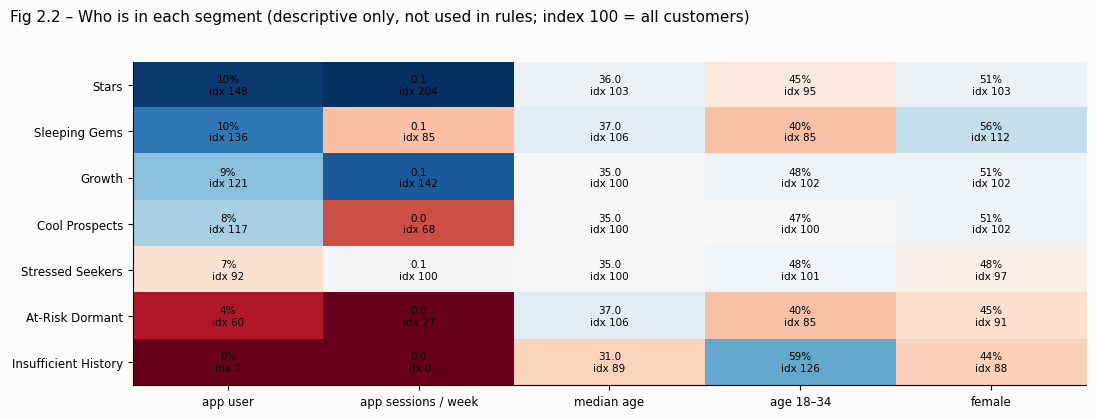

,definition (rule),customers,share,FH median [p10–p90],ENG median [p10–p90],app user,app sessions / week,median age,age 18–34,female,top region,top education
Stars,FH A/B (≥ 58) and ENG Champions/Active (≥ 56.8),266519,0.2664,73 [62–86],77 [61–95],0.1043,0.1239,36.0000,0.4451,0.5127,South (59%),High school education (53%)
Sleeping Gems,FH A/B (≥ 58) and ENG Warm/Dormant (< 56.8),163809,0.1637,68 [60–81],47 [35–55],0.0955,0.0517,37.0000,0.4012,0.5571,South (46%),High school education (54%)
Growth,FH C/D (40–58) and ENG Champions/Active (≥ 56.8),97332,0.0973,50 [42–57],74 [60–94],0.0851,0.0863,35.0000,0.4799,0.5064,South (61%),High school education (52%)
Cool Prospects,FH C/D (40–58) and ENG Warm/Dormant (< 56.8),129334,0.1293,50 [42–56],42 [34–53],0.0821,0.0413,35.0000,0.4689,0.5101,South (49%),High school education (51%)
Stressed Seekers,FH E (< 40) and ENG Champions/Active (≥ 56.8),66766,0.0667,27 [0–38],75 [61–93],0.0651,0.0610,35.0000,0.4753,0.4806,South (67%),High school education (51%)
At-Risk Dormant,FH E (< 40) and ENG Warm/Dormant (< 56.8),89906,0.0899,26 [0–38],40 [25–53],0.0422,0.0166,37.0000,0.3997,0.4547,South (56%),High school education (43%)
Insufficient History,FH N: no loan (any product) with ≥ 3 instalmen...,186862,0.1868,30 [26–44],6 [0–23],0.0000,0.0000,31.0000,0.5897,0.4390,South (56%),High school education (46%)
All customers,,1000528,1.0000,54 [27–79],52 [6–87],0.0704,0.0608,35.0000,0.4693,0.4979,South (55%),High school education (51%)


In [ ]:
# Segment definition + profile. Demographics are DESCRIPTIVE only (who the customers are, for messaging);
# they are not used in any segment or NBA rule (brief: avoid demographic factors for risk).
DEMO = ["AGE", "FLAG_INVALID_AGE", "NAME_GENDER", "REGION", "NAME_EDUCATION_TYPE", "FLAG_GMA_USER", "AVG_SESSION_PER_WEEK_2025"]
demo = (pd.read_parquet(LABEL_FILE, columns=["SKP_CLIENT"] + DEMO) if LABEL_FILE.suffix == ".parquet"
        else pd.read_csv(LABEL_FILE, usecols=["SKP_CLIENT"] + DEMO))
demo["SKP_CLIENT"] = demo["SKP_CLIENT"].astype("int64")
for c in ["AGE", "FLAG_INVALID_AGE", "FLAG_GMA_USER", "AVG_SESSION_PER_WEEK_2025"]:
    demo[c] = pd.to_numeric(demo[c], errors="coerce")
demo.loc[demo["FLAG_INVALID_AGE"] == 1, "AGE"] = np.nan
pf = df[["SKP_CLIENT", "Segment", "FH_score", "ENG_score"]].merge(demo, on="SKP_CLIENT", how="left", validate="one_to_one")
mode_share = lambda s: f"{s.value_counts(normalize=True).index[0]} ({s.value_counts(normalize=True).iloc[0]:.0%})" if s.notna().any() else "–"

DEFINITION = {
    "Stars": "FH A/B (≥ 58) and ENG Champions/Active (≥ 56.8)",
    "Sleeping Gems": "FH A/B (≥ 58) and ENG Warm/Dormant (< 56.8)",
    "Growth": "FH C/D (40–58) and ENG Champions/Active (≥ 56.8)",
    "Cool Prospects": "FH C/D (40–58) and ENG Warm/Dormant (< 56.8)",
    "Stressed Seekers": "FH E (< 40) and ENG Champions/Active (≥ 56.8)",
    "At-Risk Dormant": "FH E (< 40) and ENG Warm/Dormant (< 56.8)",
    "Insufficient History": "FH N: no loan (any product) with ≥ 3 instalments; any ENG",
}
def profile(g):
    return pd.Series({
        "customers": len(g), "share": len(g) / len(pf),
        "FH median [p10–p90]": f"{g.FH_score.median():.0f} [{g.FH_score.quantile(.1):.0f}–{g.FH_score.quantile(.9):.0f}]",
        "ENG median [p10–p90]": f"{g.ENG_score.median():.0f} [{g.ENG_score.quantile(.1):.0f}–{g.ENG_score.quantile(.9):.0f}]",
        "app user": g.FLAG_GMA_USER.mean(), "app sessions / week": g.AVG_SESSION_PER_WEEK_2025.mean(),
        "median age": g.AGE.median(), "age 18–34": g.AGE.between(18, 34.99).mean(), "female": (g.NAME_GENDER == "Female").mean(),
        "top region": mode_share(g.REGION), "top education": mode_share(g.NAME_EDUCATION_TYPE)})
prof_tbl = pd.concat([pf.groupby("Segment").apply(profile).reindex(SEG_ORDER), profile(pf).to_frame("All customers").T])
prof_tbl.insert(0, "definition (rule)", [DEFINITION.get(s, "") for s in prof_tbl.index])
prof_tbl.to_csv(OUT / "segment_profile_c3.csv", encoding="utf-8-sig")

# Index vs all customers (100 = average) for the numeric profile metrics
num = ["app user", "app sessions / week", "median age", "age 18–34", "female"]
idx = prof_tbl.loc[SEG_ORDER, num].astype(float) / prof_tbl.loc["All customers", num].astype(float) * 100
fig, ax = plt.subplots(figsize=(11, 4.2))
ax.imshow(np.clip(idx.values, 50, 150), cmap="RdBu", vmin=50, vmax=150, aspect="auto"); ax.grid(False)
ax.set_xticks(range(len(num)), num); ax.set_yticks(range(len(idx)), idx.index)
for i, s in enumerate(idx.index):
    for j, c in enumerate(num):
        v = prof_tbl.at[s, c]
        ax.text(j, i, (f"{v:.0%}" if c in ["app user", "age 18–34", "female"] else f"{v:.1f}") + f"\nidx {idx.iat[i, j]:.0f}",
                ha="center", va="center", fontsize=7.5)
fig.suptitle("Fig 2.2 – Who is in each segment (descriptive only, not used in rules; index 100 = all customers)", x=0.01, ha="left", fontsize=11)
save(fig, "2_2_profile")
prof_tbl

> **💡 Insight (Fig 2.2, bảng chân dung):**
> - **Khác biệt giữa các phân khúc nằm ở hành vi, không ở nhân khẩu học.**
>   - Tuổi trung vị chỉ dao động 35–37 ở 6 phân khúc có lịch sử trả nợ. Tỉ lệ nữ từ 45% đến 56%. Miền Nam luôn chiếm đa số (46–67%). Trình độ phổ biến nhất ở mọi nhóm là cấp 3.
>   - Ngược lại, điểm FH trung vị chênh từ 26 đến 73 và ENG từ 6 đến 77 giữa các phân khúc. Tỉ lệ dùng app chênh từ 4% (At-Risk Dormant) đến 10% (Stars).
> - **Insufficient History là nhóm trẻ nhất** (tuổi trung vị 31; 59% từ 18–34 tuổi) và gần như không dùng app → phù hợp với sản phẩm khởi đầu (BNPL hạn mức nhỏ) và cần được hướng dẫn cài app.
> - **Sleeping Gems** có tỉ lệ nữ cao nhất (56%) và ở miền Nam ít hơn các nhóm khác (46%). Thông tin này chỉ dùng để chọn thông điệp và kênh, không dùng để chấm điểm.
>
> **➡️ Ý nghĩa:** Nhân khẩu học hầu như không phân biệt được các phân khúc. Đây là bằng chứng ủng hộ việc phân khúc **theo hành vi** (FH × ENG) và **không đưa nhân khẩu học vào quy tắc**.

---
## 3. Cơ hội theo phân khúc (Yêu cầu 2)
Với mỗi khách **được chào tín dụng** (không bị chặn, phân khúc có chào bán):
- **Giải ngân kỳ vọng (60 ngày)** = xác suất chuyển đổi × số tiền kỳ vọng.
  - Xác suất chuyển đổi = tỉ lệ chuyển đổi 60 ngày **thực tế** của phân khúc ENG, đã kiểm chứng out-of-time ở Challenge 2.
  - Số tiền kỳ vọng = số tiền khoản vay gần nhất của khách cho đúng sản phẩm đó (chặn ở p90). Nếu chưa có, dùng trung vị số tiền giải ngân năm 2025 của sản phẩm.
- **Tổn thất kỳ vọng** = giải ngân kỳ vọng × tỉ lệ từng quá hạn của nhóm FH. Không nhân (1 − rủi ro) vào giá trị vì rủi ro rất nhỏ (< 7%) nên gần như không đổi thứ hạng. Rủi ro được kiểm soát bằng **điều kiện chặn** ở §4.

Sản phẩm dùng để tính số tiền là sản phẩm do bảng quy tắc ở §4 chọn, nên §3 được tính sau khi chạy quy tắc (ô dưới đây chỉ định nghĩa hàm).

In [8]:
def ticket_for(frame, product_col):
    """Expected loan amount for the recommended product: customer's last amount for it (capped at p90), else 2025 product median."""
    med = frame[product_col].map(TICKET["median_amount"])
    p90 = frame[product_col].map(TICKET["p90_amount"])
    own = pd.Series(np.nan, index=frame.index)
    for p in OFFER_PRODUCTS:
        m = frame[product_col] == p
        own[m] = frame.loc[m, f"last_amt_{p}"]
    return own.clip(upper=p90).fillna(med)

FH_RISK = df.groupby("FH_segment")["ever_overdue"].mean()     # share of customers in the FH group ever overdue
FH_RISK

FH_segment
A · Rất khỏe                 0.0073
B · Khỏe                     0.0118
C · Trung bình               0.0159
D · Yếu                      0.0298
E · Rủi ro cao               0.2689
N · Chưa đủ lịch sử trả nợ   0.0006
Name: ever_overdue, dtype: float64

---
## 4. Next Best Action: bảng quy tắc (Yêu cầu 3)
Quy tắc chạy **theo thứ tự ưu tiên**; khách khớp quy tắc nào trước thì dừng ở đó.

| Thứ tự | Quy tắc | Điều kiện | Hành động |
|---|---|---|---|
| **R1** | Chặn rủi ro | khoản vay đang chạy từng quá hạn, nợ xấu, hoặc bị gọi thu nợ trong 90 ngày | **Không bán**. Hỗ trợ trả nợ: nhắc lịch, tư vấn cơ cấu |
| **R2** | FH thấp | Stressed Seekers / At-Risk Dormant | **Không cấp mới**. Stressed: tư vấn tài chính, nhắc trả đúng hạn · At-Risk: theo dõi sớm, ngừng marketing |
| **R3** | Nuôi dưỡng | Cool Prospects | Nội dung, hướng dẫn app; chưa chào tín dụng |
| **R4** | Chào bán | Stars · Sleeping Gems · Growth · Insufficient History | Ưu đãi theo phân khúc (bảng dưới). Insufficient History: hạn mức nhỏ BNPL/CD, tăng dần sau mỗi kỳ trả đúng hạn |

**Điều chỉnh theo hành vi từng khách** (chỉ cho R4):
- **Thời điểm**:
  - Vừa giải ngân dưới 60 ngày → **hoãn** đến ngày thứ 60.
  - Khoản vay kết thúc trong ±60 ngày → **chào vay tiếp ngay**.
  - Còn lại → chào ngay.
- **Sản phẩm**: sản phẩm khách **scoring trong 90 ngày** → lead gần nhất trong 180 ngày → sản phẩm đầu tiên khách chưa có trong danh sách của phân khúc. Sản phẩm phải nằm trong danh sách được phép của phân khúc.
- **Kênh**:
  - ENG cao → telesales + app.
  - ENG thấp → app push / SMS. Lý do: ở Challenge 2, tỉ lệ *quan tâm hoặc đồng ý* mỗi cuộc gọi kết nối là 6,1% ở Champions so với 2,7% ở Dormant, nên gọi điện cho khách ENG thấp tốn khoảng 2,2 lần chi phí cho mỗi khách quan tâm.

In [9]:
OFFER = {   # segment: (action, allowed products, default ladder, why)
    "Stars": ("Pre-approved top-up / cross-sell offer", OFFER_PRODUCTS, ["CL", "CC", "BNPL"],
              "healthy and actively engaging: highest expected conversion at the lowest risk"),
    "Sleeping Gems": ("Re-activation: pre-approved offer with a time limit", OFFER_PRODUCTS, ["CL", "CC", "BNPL"],
                      "healthy but drifting away: a cheap digital nudge before they leave"),
    "Growth": ("Right-sized offer with down payment, moderate limit", ["CD", "TW", "BNPL", "CC"], ["CD", "BNPL", "CC"],
               "interested but only moderately healthy: grow carefully with limits matched to capacity"),
    "Insufficient History": ("Starter limit: small BNPL / consumer-durable loan, limit steps up after each on-time instalment", ["BNPL", "CD"], ["BNPL", "CD"],
              "no repayment evidence yet (no loan with ≥ 3 instalments): start small and raise the limit as on-time payments accumulate"),
}
NO_OFFER = {
    "Stressed Seekers": ("No new credit: financial counselling + on-time repayment reminders", "App / SMS",
                         "engaged but financially weak: more credit would raise default risk"),
    "At-Risk Dormant": ("No marketing: early-warning monitoring", "Monitoring only",
                        "weak health and no engagement: protect the portfolio, avoid marketing cost"),
    "Cool Prospects": ("Low-cost nurture: content and app onboarding, no credit push", "App / SMS",
                       "moderate health and low interest: keep warm cheaply until a need signal appears"),
}

blocked = (df["active_overdue"] == 1) | (df["bad_debt"] == 1) | (df["collection_90d"] == 1)
df["rule"] = np.select([blocked, df["Segment"].isin(["Stressed Seekers", "At-Risk Dormant"]), df["Segment"] == "Cool Prospects"],
                       ["R1 risk block", "R2 weak FH", "R3 nurture"], default="R4 offer")
offer = df["rule"] == "R4 offer"

# --- product
def pick_product(r):
    allowed, ladder = OFFER[r.Segment][1], OFFER[r.Segment][2]
    if isinstance(r.last_scored_product, str) and r.last_scored_product in allowed and r.days_since_scoring <= 90:
        return r.last_scored_product, f"scored {r.last_scored_product} {int(r.days_since_scoring)} days ago"
    if isinstance(r.last_lead_product, str) and r.last_lead_product in allowed and r.days_since_lead <= 180:
        return r.last_lead_product, f"recent lead for {r.last_lead_product}"
    for p in ladder:
        if getattr(r, f"held_{p}") == 0:
            return p, f"does not hold {p} yet"
    return ladder[0], f"repeat {ladder[0]}"

t0 = time.time()
picked = [pick_product(r) for r in df.loc[offer, ["Segment", "last_scored_product", "days_since_scoring", "last_lead_product", "days_since_lead"]
                                            + [f"held_{p}" for p in OFFER_PRODUCTS]].itertuples(index=False)]
df["NBA_product"], df["product_reason"] = "None", ""
df.loc[offer, "NBA_product"] = [p for p, _ in picked]
df.loc[offer, "product_reason"] = [w for _, w in picked]

# --- timing
defer = offer & (df["days_since_booking"] < 60)
renew = offer & ~defer & ((df["days_to_loan_end"].between(0, 60)) | (df["days_since_loan_end"].between(0, 60)))
df["NBA_timing"] = np.select([~offer, defer, renew], ["n/a", "Defer", "Now – loan ending: renewal"], default="Now")
defer_date = (pd.Timestamp(SNAPSHOT) + pd.to_timedelta(60 - df["days_since_booking"].fillna(60), unit="D")).dt.strftime("%d/%m/%Y")
df.loc[defer, "NBA_timing"] = "Defer to " + defer_date[defer]

# --- action and channel
df["NBA_action"] = np.select([df["rule"] == "R1 risk block", offer],
                             ["Repayment support: no sales, reminder and restructuring advice",
                              df["Segment"].map(lambda s: OFFER.get(s, ("",))[0])],
                             default=df["Segment"].map(lambda s: NO_OFFER.get(s, ("",))[0]))
df["NBA_channel"] = np.select([df["rule"] == "R1 risk block", offer & (df["ENG_tier"] == "High"), offer],
                              ["Collection-care team / SMS", "Telesales + app", "App push / SMS"],
                              default=df["Segment"].map(lambda s: NO_OFFER.get(s, ("", "n/a"))[1]))

# --- opportunity (only for customers who receive a credit offer)
df["ticket"] = np.where(offer, ticket_for(df, "NBA_product"), 0.0)
df["p_conv"] = df["ENG_segment"].map(P_CONV)
df["expected_disbursement"] = np.where(offer, df["p_conv"] * df["ticket"], 0.0)
df["expected_loss"] = df["expected_disbursement"] * df["FH_segment"].map(FH_RISK)
print(f"rules applied in {time.time() - t0:.0f}s")
pd.crosstab(df["Segment"], df["rule"]).reindex(SEG_ORDER)

rules applied in 11s


rule,R1 risk block,R2 weak FH,R3 nurture,R4 offer
Segment,,,,
Stars,7422,0,0,259097
Sleeping Gems,1088,0,0,162721
Growth,3217,0,0,94115
Cool Prospects,1757,0,127577,0
Stressed Seekers,11163,55603,0,0
At-Risk Dormant,18738,71168,0,0
Insufficient History,757,0,0,186105


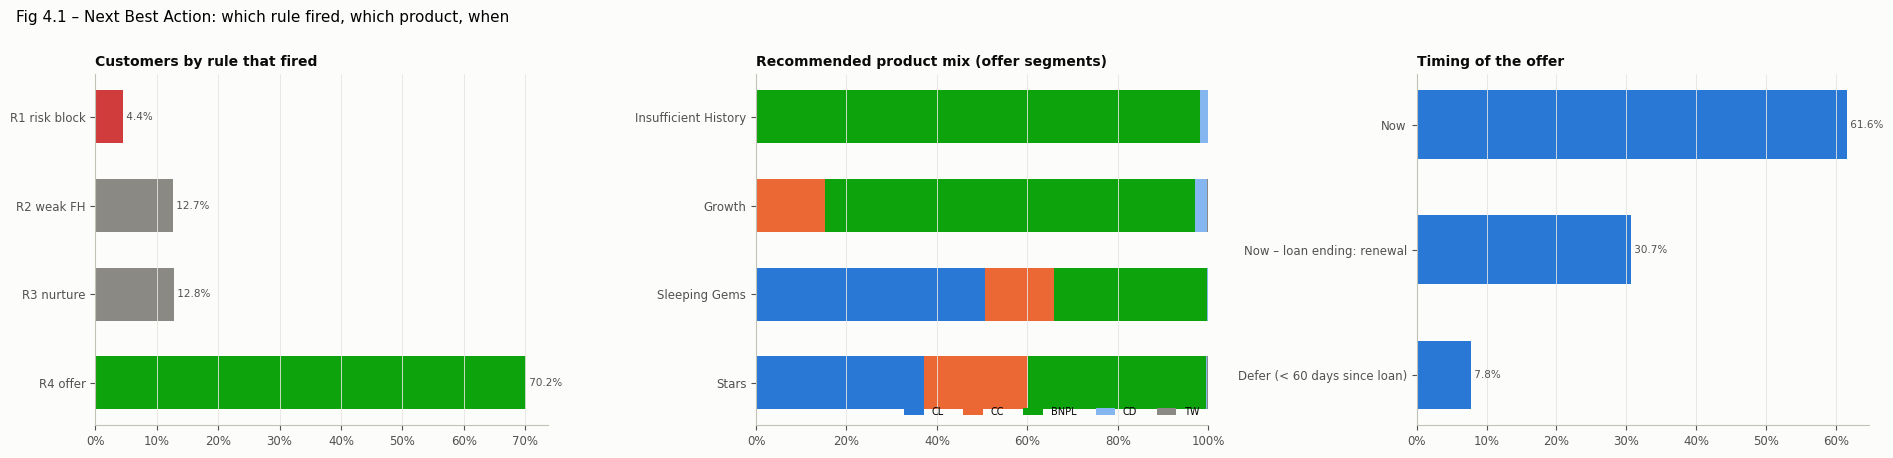

NBA_channel,App / SMS,App push / SMS,Collection-care team / SMS,Monitoring only,Telesales + app
NBA_action,,,,,
"Low-cost nurture: content and app onboarding, no credit push",127577,0,0,0,0
No marketing: early-warning monitoring,0,0,0,71168,0
No new credit: financial counselling + on-time repayment reminders,55603,0,0,0,0
Pre-approved top-up / cross-sell offer,0,0,0,0,259097
Re-activation: pre-approved offer with a time limit,0,162721,0,0,0
"Repayment support: no sales, reminder and restructuring advice",0,0,44142,0,0
"Right-sized offer with down payment, moderate limit",0,0,0,0,94115
"Starter limit: small BNPL / consumer-durable loan, limit steps up after each on-time instalment",0,181638,0,0,4467


In [10]:
fig, axes = plt.subplots(1, 3, figsize=(19, 4.6))
ax = axes[0]
r = df["rule"].value_counts(normalize=True).sort_index()
ax.barh(r.index[::-1], r.values[::-1], color=[GREEN if "offer" in i else RED if "block" in i else GREY for i in r.index[::-1]], height=0.6)
bar_labels(ax, r.values[::-1], horizontal=True); ax.xaxis.set_major_formatter(PCT); ax.grid(axis="y", visible=False)
ax.set_title("Customers by rule that fired", loc="left")
ax = axes[1]
pp = pd.crosstab(df.loc[offer, "Segment"], df.loc[offer, "NBA_product"], normalize="index").reindex(
    index=[s for s in SEG_ORDER if s in OFFER], columns=OFFER_PRODUCTS).fillna(0)
left = np.zeros(len(pp))
for p, c in zip(OFFER_PRODUCTS, [BLUE, ORANGE, GREEN, BLUE_L, GREY]):
    ax.barh(pp.index, pp[p], left=left, color=c, label=p, height=0.6); left += pp[p].values
ax.xaxis.set_major_formatter(PCT); ax.legend(frameon=False, ncol=5, fontsize=7, loc="lower right"); ax.grid(axis="y", visible=False)
ax.set_title("Recommended product mix (offer segments)", loc="left")
ax = axes[2]
tm = df.loc[offer, "NBA_timing"].str.replace(r"Defer to .*", "Defer (< 60 days since loan)", regex=True).value_counts(normalize=True)
ax.barh(tm.index[::-1], tm.values[::-1], color=BLUE, height=0.55)
bar_labels(ax, tm.values[::-1], horizontal=True); ax.xaxis.set_major_formatter(PCT); ax.grid(axis="y", visible=False)
ax.set_title("Timing of the offer", loc="left")
fig.suptitle("Fig 4.1 – Next Best Action: which rule fired, which product, when", x=0.01, ha="left", fontsize=11)
save(fig, "4_1_nba_mix")
pd.crosstab(df["NBA_action"], df["NBA_channel"])

> **💡 Insight (Fig 4.1):**
> - **Chặn rủi ro trước (R1): 44.142 khách (4,4%)**: có khoản vay đang chạy từng quá hạn, có nợ xấu, hoặc bị gọi thu nợ trong 90 ngày. Quy tắc này bắt được cả **7.422 khách Stars** mà nếu chỉ nhìn phân khúc sẽ bị chào bán nhầm.
> - **Khách được chào tín dụng (R4): 702.038 khách (70%).**
>   - **Thời điểm:** 62% chào ngay, **31% chào vay tiếp vì khoản vay sắp hoặc vừa kết thúc**, 8% hoãn vì vừa giải ngân dưới 60 ngày.
>   - **Sản phẩm:**
>     - Stars: BNPL 39%, CL 37%, CC 23%.
>     - Sleeping Gems: CL 51%.
>     - Growth: BNPL 82% (đã có CD và chỉ được chào sản phẩm có trả trước hoặc hạn mức nhỏ).
>     - Insufficient History: BNPL 98%. BNPL vừa là sản phẩm, vừa là công cụ tích lũy lịch sử trả nợ.
> - **Kênh:** telesales dành cho khách ENG cao (Stars, Growth). Khách ENG thấp (Sleeping Gems, phần lớn Insufficient History) nhận app/SMS.
>
> **➡️ Ý nghĩa:** Mỗi khách nhận đúng **một** hành động, có sản phẩm, kênh và thời điểm cụ thể. Rủi ro được chặn **trước** khi xét cơ hội.

### 3.1 Cơ hội theo phân khúc (kết quả của §3 sau khi chọn sản phẩm)

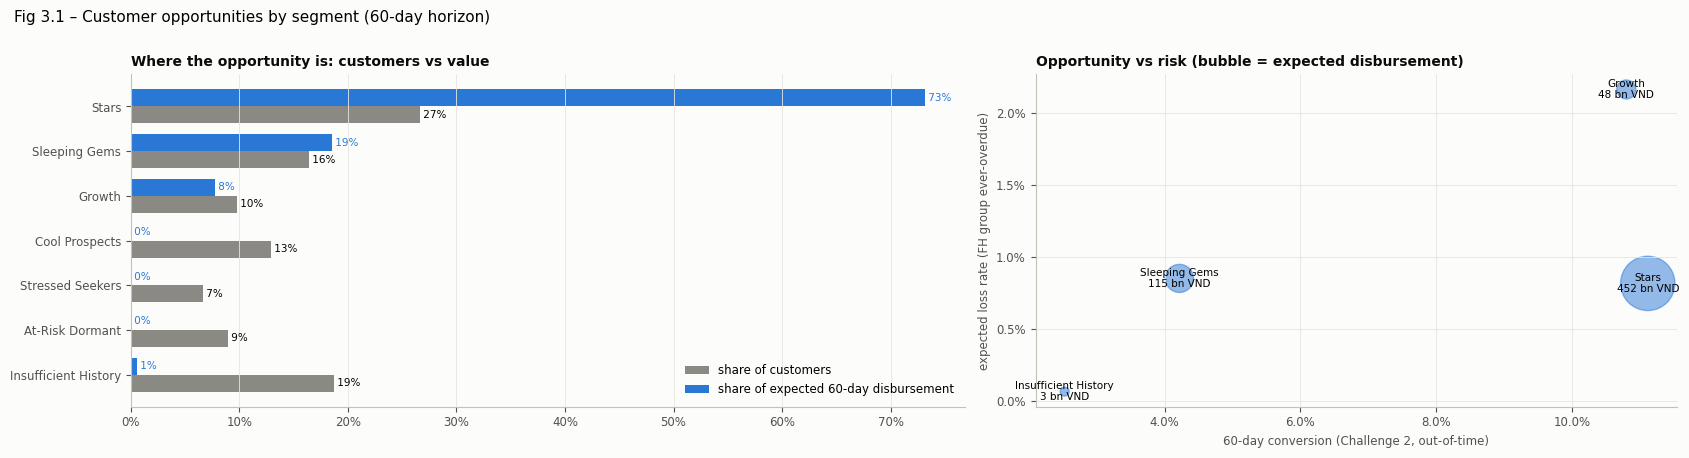

,customers,avg_FH,avg_ENG,ever_overdue,blocked,p_conv_60d,offered,expected_disbursement_bn,expected_loss_bn,share_customers,share_value,loss_rate,value_per_customer_m
Segment,,,,,,,,,,,,,
Stars,266519,73.4719,77.1358,0.0118,0.0278,0.1112,0.9722,451.9461,3.6853,0.2664,0.7318,0.0082,1.6957
Sleeping Gems,163809,69.6672,45.4201,0.0030,0.0066,0.0422,0.9934,114.5409,0.9738,0.1637,0.1855,0.0085,0.6992
Growth,97332,50.0254,75.7417,0.0337,0.0331,0.1080,0.9669,47.5851,1.0286,0.0973,0.0771,0.0216,0.4889
Cool Prospects,129334,49.8190,41.4631,0.0141,0.0136,0.0385,0.0000,0.0000,0.0000,0.1293,0.0000,NaN,0.0000
Stressed Seekers,66766,23.2727,75.7913,0.2681,0.1672,0.1076,0.0000,0.0000,0.0000,0.0667,0.0000,NaN,0.0000
At-Risk Dormant,89906,23.1394,39.1009,0.2695,0.2084,0.0364,0.0000,0.0000,0.0000,0.0899,0.0000,NaN,0.0000
Insufficient History,186862,31.9196,11.3496,0.0006,0.0041,0.0253,0.9959,3.4805,0.0022,0.1868,0.0056,0.0006,0.0186


In [11]:
seg = df.groupby("Segment").agg(
    customers=("SKP_CLIENT", "size"), avg_FH=("FH_score", "mean"), avg_ENG=("ENG_score", "mean"),
    ever_overdue=("ever_overdue", "mean"), blocked=("rule", lambda s: (s == "R1 risk block").mean()),
    p_conv_60d=("p_conv", "mean"), offered=("rule", lambda s: (s == "R4 offer").mean()),
    expected_disbursement_bn=("expected_disbursement", lambda s: s.sum() / 1e9),
    expected_loss_bn=("expected_loss", lambda s: s.sum() / 1e9)).reindex(SEG_ORDER)
seg["share_customers"] = seg["customers"] / seg["customers"].sum()
seg["share_value"] = seg["expected_disbursement_bn"] / seg["expected_disbursement_bn"].sum()
seg["loss_rate"] = seg["expected_loss_bn"] / seg["expected_disbursement_bn"].replace(0, np.nan)
seg["value_per_customer_m"] = seg["expected_disbursement_bn"] * 1e3 / seg["customers"]

fig, axes = plt.subplots(1, 2, figsize=(17, 4.6), gridspec_kw={"width_ratios": [1.3, 1]})
ax = axes[0]
y = np.arange(len(seg)); w = 0.38
ax.barh(y + w / 2, seg["share_customers"], w, color=GREY, label="share of customers")
ax.barh(y - w / 2, seg["share_value"], w, color=BLUE, label="share of expected 60-day disbursement")
for i, (c, v) in enumerate(zip(seg["share_customers"], seg["share_value"])):
    ax.text(c, i + w / 2, f" {c:.0%}", va="center", fontsize=7.5); ax.text(v, i - w / 2, f" {v:.0%}", va="center", fontsize=7.5, color=BLUE)
ax.set_yticks(y, seg.index); ax.invert_yaxis(); ax.xaxis.set_major_formatter(PCT); ax.legend(frameon=False, loc="lower right")
ax.grid(axis="y", visible=False); ax.set_title("Where the opportunity is: customers vs value", loc="left")
ax = axes[1]
o = seg[seg["expected_disbursement_bn"] > 0]
ax.scatter(o["p_conv_60d"], o["loss_rate"], s=o["expected_disbursement_bn"] / o["expected_disbursement_bn"].max() * 1500 + 30,
           color=BLUE, alpha=0.5, edgecolor=BLUE)
for name, r in o.iterrows():
    ax.annotate(f"{name}\n{r.expected_disbursement_bn:,.0f} bn VND", (r.p_conv_60d, r.loss_rate), fontsize=7.5, ha="center", va="center")
ax.xaxis.set_major_formatter(PCT1); ax.yaxis.set_major_formatter(PCT1)
ax.set_xlabel("60-day conversion (Challenge 2, out-of-time)"); ax.set_ylabel("expected loss rate (FH group ever-overdue)")
ax.set_title("Opportunity vs risk (bubble = expected disbursement)", loc="left")
fig.suptitle("Fig 3.1 – Customer opportunities by segment (60-day horizon)", x=0.01, ha="left", fontsize=11)
save(fig, "3_1_opportunity")
seg.to_csv(OUT / "segment_summary.csv", encoding="utf-8-sig")
seg

> **💡 Insight (Fig 3.1):** tổng giải ngân kỳ vọng trong 60 ngày khoảng **618 tỷ VND**, tổn thất kỳ vọng khoảng 5,7 tỷ (0,9%).
> - **Stars chiếm 27% khách nhưng 73% giá trị** (452 tỷ, khoảng 1,7 triệu/khách), tỉ lệ tổn thất chỉ 0,8%.
> - **Sleeping Gems:** 16% khách, 19% giá trị (115 tỷ). Đây là nguồn lớn thứ hai, có thể tiếp cận bằng kênh số chi phí thấp.
> - **Growth:** 8% giá trị (48 tỷ), nhưng tỉ lệ tổn thất cao gấp gần 3 lần (2,2%). Đúng với thiết kế: chỉ chào khoản nhỏ, có trả trước.
> - **Insufficient History:** dưới 1% giá trị (khoản BNPL nhỏ, chuyển đổi 2,5%). Mục tiêu với nhóm này là **xây lịch sử trả nợ**, không phải doanh số trước mắt.
> - Ba phân khúc không chào bán (Stressed Seekers, At-Risk Dormant, Cool Prospects) **cố ý** có giá trị bằng 0.
>
> **➡️ Ý nghĩa:** Thứ tự ưu tiên là **Stars → Sleeping Gems → Growth**. 43% khách (Stars + Sleeping Gems) mang về khoảng **92%** giá trị kỳ vọng mà không tăng rủi ro.
>
> ⚠️ Giá trị là **số tiền giải ngân**, không phải lợi nhuận. Xác suất chuyển đổi lấy theo phân khúc ENG (đã kiểm chứng out-of-time), chưa theo từng ô FH × ENG.

### 3.2 Cơ hội cụ thể của từng phân khúc
Bảng dưới gom kết quả §3 và §4 cho từng phân khúc: **loại cơ hội**, số khách được chào bán, sản phẩm và kênh chính, thời điểm chào, và giá trị kỳ vọng.

In [ ]:
# Concrete opportunity per segment: what we sell, to how many, through which channel, when, and what it is worth
opp_type = {"Stars": "Cross-sell / top-up now", "Sleeping Gems": "Re-activate (digital)", "Growth": "Controlled growth (small, down payment)",
            "Insufficient History": "Build repayment history (starter BNPL/CD)", "Cool Prospects": "Nurture (no credit yet)",
            "Stressed Seekers": "Protect: counselling, no new credit", "At-Risk Dormant": "Protect: monitor, no marketing"}
o = df.assign(offered=df["NBA_product"] != "None",
              renewal=df["NBA_timing"].str.startswith("Now – loan"), deferred=df["NBA_timing"].str.startswith("Defer"),
              blocked=df["NBA_action"].str.startswith("Repayment support"))
def opp(g):
    off = g[g.offered]
    mix = off.NBA_product.value_counts(normalize=True)
    return pd.Series({
        "opportunity": opp_type[g.name], "customers": len(g), "offered": len(off), "risk-blocked": int(g.blocked.sum()),
        "main products": ", ".join(f"{p} {v:.0%}" for p, v in mix.head(2).items()) if len(off) else "–",
        "main channel": g.NBA_channel.value_counts().index[0],
        "renewal timing": off.renewal.mean() if len(off) else np.nan, "deferred": off.deferred.mean() if len(off) else np.nan,
        "exp. disbursement (bn VND)": g.expected_disbursement.sum() / 1e9,
        "per offered customer (m VND)": off.expected_disbursement.mean() / 1e6 if len(off) else 0.0,
        "exp. loss rate": g.expected_loss.sum() / g.expected_disbursement.sum() if g.expected_disbursement.sum() else np.nan})
opp_tbl = o.groupby("Segment").apply(opp).reindex(SEG_ORDER)
opp_tbl["share of value"] = opp_tbl["exp. disbursement (bn VND)"] / opp_tbl["exp. disbursement (bn VND)"].sum()
opp_tbl.to_csv(OUT / "segment_opportunity.csv", encoding="utf-8-sig")
opp_tbl

,opportunity,customers,offered,risk-blocked,main products,main channel,renewal timing,deferred,exp. disbursement (bn VND),per offered customer (m VND),exp. loss rate,share of value
Segment,,,,,,,,,,,,
Stars,Cross-sell / top-up now,266519,259097,7422,"BNPL 39%, CL 37%",Telesales + app,0.3812,0.1475,451.9461,1.7443,0.0082,0.7318
Sleeping Gems,Re-activate (digital),163809,162721,1088,"CL 51%, BNPL 34%",App push / SMS,0.4939,0.0005,114.5408,0.7039,0.0085,0.1855
Growth,"Controlled growth (small, down payment)",97332,94115,3217,"BNPL 82%, CC 15%",Telesales + app,0.3823,0.1414,47.5851,0.5056,0.0216,0.0771
Cool Prospects,Nurture (no credit yet),129334,0,1757,–,App / SMS,NaN,NaN,0.0000,0.0000,NaN,0.0000
Stressed Seekers,"Protect: counselling, no new credit",66766,0,11163,–,App / SMS,NaN,NaN,0.0000,0.0000,NaN,0.0000
At-Risk Dormant,"Protect: monitor, no marketing",89906,0,18738,–,Monitoring only,NaN,NaN,0.0000,0.0000,NaN,0.0000
Insufficient History,Build repayment history (starter BNPL/CD),186862,186105,757,"BNPL 98%, CD 2%",App push / SMS,0.0008,0.0152,3.4806,0.0187,0.0006,0.0056


> **💡 Insight (bảng cơ hội):**
>
> | Phân khúc | Loại cơ hội | Chào ai, chào gì | Kênh · thời điểm | Giá trị kỳ vọng 60 ngày |
> |---|---|---|---|---|
> | ⭐ **Stars** | **Bán chéo / vay thêm ngay** | 259.097 khách (sau khi chặn 7.422 khách rủi ro). BNPL 39%, CL 37%, CC 23%: sản phẩm khách vừa tìm hiểu, hoặc sản phẩm chưa có | Telesales + app. **38% chào vay tiếp đúng lúc khoản vay kết thúc**, 15% hoãn vì vừa giải ngân | **452 tỷ (73%)**, 1,74 triệu/khách, tổn thất 0,8% |
> | 💎 **Sleeping Gems** | **Kích hoạt lại bằng kênh số** | 162.721 khách. CL 51%, BNPL 34%; ưu đãi duyệt sẵn có thời hạn | App push / SMS (rẻ hơn telesales). 49% có khoản vay sắp hoặc vừa kết thúc | **115 tỷ (19%)**, 0,70 triệu/khách, tổn thất 0,9% |
> | 🌱 **Growth** | **Tăng trưởng có kiểm soát** | 94.115 khách. BNPL 82%, CC 15%; hạn mức vừa, có trả trước | Telesales + app. 38% chào vay tiếp | **48 tỷ (8%)**, 0,51 triệu/khách, tổn thất **2,2%** (cao nhất) |
> | 🌱 **Insufficient History** | **Xây lịch sử trả nợ** | 186.105 khách. BNPL hạn mức nhỏ 98%, CD 2%; tăng hạn mức sau mỗi kỳ trả đúng hạn | App push / SMS | 3,5 tỷ (< 1%). Giá trị nằm ở **tương lai**: khách đủ 3 kỳ trả sẽ được chấm FH và chuyển sang nhóm có thể bán |
> | ❄️ **Cool Prospects** | **Nuôi dưỡng, chưa chào tín dụng** | 129.334 khách: nội dung, hướng dẫn app | App / SMS chi phí thấp | 0 (cố ý). Khi có tín hiệu nhu cầu (lead, scoring) và ENG lên mức cao thì chuyển sang **Growth** |
> | ⚠️ **Stressed Seekers** | **Bảo vệ: tư vấn, không cấp mới** | 66.766 khách (11.163 đã bị chặn rủi ro) | App / SMS: nhắc trả nợ, tư vấn tài chính | 0 (cố ý). Cơ hội là **giảm tổn thất**, không phải doanh số |
> | 🛑 **At-Risk Dormant** | **Bảo vệ: theo dõi, ngừng marketing** | 89.906 khách (18.738 đã bị chặn rủi ro) | Chỉ theo dõi | 0 (cố ý). Tiết kiệm chi phí marketing |
>
> **➡️ Ý nghĩa:** Có **3 cơ hội doanh số** (Stars → Sleeping Gems → Growth, chiếm 99% giá trị), **1 cơ hội dài hạn** (Insufficient History: tạo khách mới có lịch sử trả nợ) và **3 nhóm ưu tiên kiểm soát rủi ro và chi phí**. Đề xuất triển khai theo thứ tự: Stars (đúng thời điểm khoản vay kết thúc) → Sleeping Gems (kênh số, rủi ro thấp nhất) → Growth (khoản nhỏ, có trả trước).

---
## 5. Why this action? (Yêu cầu 4)
### 5.1 Bằng chứng cho từng phân khúc
Ngoài các con số ở §2–§3, kiểm tra thêm bằng **cuộc gọi sau ngày chốt** (dữ liệu chưa dùng ở bất kỳ bước nào): mỗi phân khúc phản hồi với cuộc gọi bán hàng ra sao, và có bị gọi thu nợ không.
Lưu ý: bảng CALL kéo dài đến 08/2026, cần BTC xác nhận trước khi dùng làm bằng chứng chính.

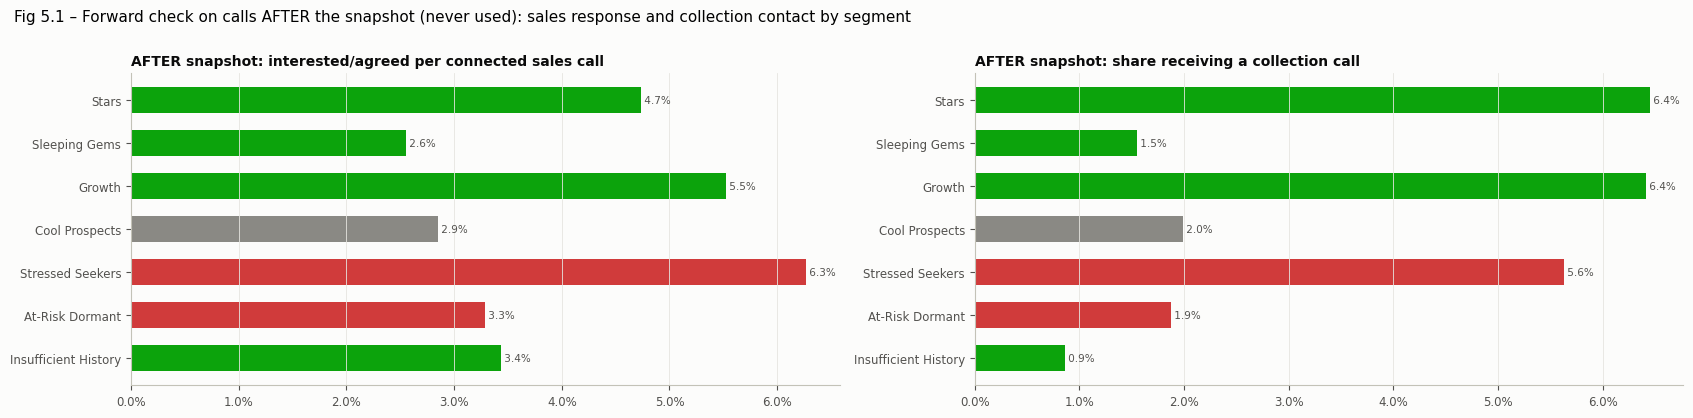

,customers,share_customers,avg_FH,avg_ENG,ever_overdue,p_conv_60d,share_value,loss_rate,positive_per_connected_call,collection_after
Segment,,,,,,,,,,
Stars,266519,0.2664,73.4719,77.1358,0.0118,0.1112,0.7318,0.0082,0.0473,0.0645
Sleeping Gems,163809,0.1637,69.6672,45.4201,0.0030,0.0422,0.1855,0.0085,0.0255,0.0155
Growth,97332,0.0973,50.0254,75.7417,0.0337,0.1080,0.0771,0.0216,0.0553,0.0642
Cool Prospects,129334,0.1293,49.8190,41.4631,0.0141,0.0385,0.0000,NaN,0.0285,0.0199
Stressed Seekers,66766,0.0667,23.2727,75.7913,0.2681,0.1076,0.0000,NaN,0.0627,0.0563
At-Risk Dormant,89906,0.0899,23.1394,39.1009,0.2695,0.0364,0.0000,NaN,0.0329,0.0187
Insufficient History,186862,0.1868,31.9196,11.3496,0.0006,0.0253,0.0056,0.0006,0.0344,0.0086


In [12]:
post = q(f"""
SELECT client AS SKP_CLIENT,
       COUNT(*) FILTER (WHERE NOT is_collection AND NOT is_inbound AND is_connected) AS sales_connected,
       COUNT(*) FILTER (WHERE NOT is_collection AND response IN ('INTERESTED', 'AGREED')) AS sales_positive,
       MAX(CASE WHEN is_collection THEN 1 ELSE 0 END) AS got_collection_call
FROM call WHERE t_call >= TIMESTAMP '{SNAPSHOT}' GROUP BY 1""")
ev = df[["SKP_CLIENT", "Segment"]].merge(post, on="SKP_CLIENT", how="left").fillna(0)
evid = ev.groupby("Segment").agg(sales_connected=("sales_connected", "sum"), sales_positive=("sales_positive", "sum"),
                                 collection_after=("got_collection_call", "mean")).reindex(SEG_ORDER)
evid["positive_per_connected_call"] = evid["sales_positive"] / evid["sales_connected"]
seg = seg.join(evid[["positive_per_connected_call", "collection_after"]])

fig, axes = plt.subplots(1, 2, figsize=(17, 4.2))
for ax, col, title in [(axes[0], "positive_per_connected_call", "AFTER snapshot: interested/agreed per connected sales call"),
                       (axes[1], "collection_after", "AFTER snapshot: share receiving a collection call")]:
    ax.barh(seg.index[::-1], seg[col][::-1], color=[GREEN if s in OFFER else RED if s in ("Stressed Seekers", "At-Risk Dormant") else GREY
                                                     for s in seg.index[::-1]], height=0.6)
    bar_labels(ax, seg[col][::-1].values, horizontal=True); ax.xaxis.set_major_formatter(PCT1); ax.grid(axis="y", visible=False)
    ax.set_title(title, loc="left")
fig.suptitle("Fig 5.1 – Forward check on calls AFTER the snapshot (never used): sales response and collection contact by segment",
             x=0.01, ha="left", fontsize=11)
save(fig, "5_1_forward_check")
seg[["customers", "share_customers", "avg_FH", "avg_ENG", "ever_overdue", "p_conv_60d", "share_value", "loss_rate",
     "positive_per_connected_call", "collection_after"]]

> **💡 Insight (Fig 5.1, bảng bằng chứng):**
> - **Phản hồi với cuộc gọi bán hàng sau ngày chốt** khớp với trục ENG:
>   - Các phân khúc ENG cao có tỉ lệ *quan tâm hoặc đồng ý* mỗi cuộc gọi kết nối từ 4,7% đến 6,3%: Stars 4,7%, Growth 5,5%, Stressed Seekers 6,3%.
>   - Các phân khúc ENG thấp chỉ từ 2,6% đến 3,4%: Sleeping Gems 2,6%, Cool Prospects 2,9%, At-Risk Dormant 3,3%, Insufficient History 3,4%.
> - **Stressed Seekers phản hồi tích cực nhất (6,3%).** Đây là bằng chứng rõ nhất cho quy tắc chặn: nhóm này *chủ động muốn vay thêm* dù 27% đã từng quá hạn.
> - **Cuộc gọi thu nợ sau ngày chốt không phân biệt được rủi ro:** Stars 6,5%, Stressed Seekers 5,6%. Nhiều khả năng bảng CALL gộp cả cuộc gọi *nhắc lịch thông thường* cho mọi khách đang có khoản vay, nên chỉ số này không được dùng làm bằng chứng.
>
> **➡️ Ý nghĩa:** Bằng chứng cho mỗi hành động:
> - *Chào bán Stars*: chuyển đổi 11,1%, tổn thất 0,8%.
> - *Chặn Stressed Seekers*: muốn vay nhất nhưng 27% từng quá hạn.
> - *Kênh số cho ENG thấp*: phản hồi qua điện thoại chỉ bằng khoảng một nửa.
>
> Cần BTC xác nhận dữ liệu CALL sau ngày chốt.

### 5.2 Câu giải thích cho từng khách
Mỗi khách có một câu ghép từ **điểm FH**, **điểm ENG**, **quy tắc đã kích hoạt** và **lý do chọn sản phẩm / thời điểm / kênh**.

In [13]:
why_seg = {**{k: v[3] for k, v in OFFER.items()}, **{k: v[2] for k, v in NO_OFFER.items()}}
block_reason = np.select([df["active_overdue"] == 1, df["bad_debt"] == 1, df["collection_90d"] == 1],
                         ["a running loan has been overdue", "has a bad-debt contract", "received a collection call in the last 90 days"], default="")
timing_reason = np.select([df["NBA_timing"].str.startswith("Defer"), df["NBA_timing"].str.startswith("Now – loan ending")],
                          [" Wait: loan disbursed " + df["days_since_booking"].fillna(0).astype(int).astype(str) + " days ago (customers rarely return right after a loan).",
                           " Now: a loan ends within 60 days (customers with an ended loan return ×2 more often)."], default="")
df["NBA_why"] = ("FH " + df["FH_score"].round(0).astype(int).astype(str) + " (" + df["FH_segment"] + ") × ENG "
                 + df["ENG_score"].round(0).astype(int).astype(str) + " (" + df["ENG_segment"] + ") → " + df["Segment"] + ". ")
df["NBA_why"] += np.where(df["rule"] == "R1 risk block", "Blocked: " + pd.Series(block_reason, index=df.index) + ".",
                          df["Segment"].map(why_seg) + ".")
df["NBA_why"] += np.where(offer, " Product " + df["NBA_product"] + ": " + df["product_reason"] + "." + pd.Series(timing_reason, index=df.index)
                          + " Channel: " + df["NBA_channel"] + ".", "")
pd.set_option("display.max_colwidth", 260)
df.loc[df.groupby("Segment").sample(1, random_state=SEED).index, ["SKP_CLIENT", "Segment", "NBA_action", "NBA_why"]].set_index("SKP_CLIENT")

,Segment,NBA_action,NBA_why
SKP_CLIENT,,,
127405076,At-Risk Dormant,No marketing: early-warning monitoring,"FH 0 (E · Rủi ro cao) × ENG 52 (Warm) → At-Risk Dormant. weak health and no engagement: protect the portfolio, avoid marketing cost."
1407973,Cool Prospects,"Low-cost nurture: content and app onboarding, no credit push",FH 51 (C · Trung bình) × ENG 40 (Warm) → Cool Prospects. moderate health and low interest: keep warm cheaply until a need signal appears.
8743966,Growth,"Right-sized offer with down payment, moderate limit",FH 48 (D · Yếu) × ENG 75 (Active) → Growth. interested but only moderately healthy: grow carefully with limits matched to capacity. Product BNPL: scored BNPL 9 days ago. Now: a loan ends within 60 days (customers with an ended loan return ×2 more often). C...
126091985,Insufficient History,"Starter limit: small BNPL / consumer-durable loan, limit steps up after each on-time instalment",FH 21 (N · Chưa đủ lịch sử trả nợ) × ENG 66 (Active) → Insufficient History. no repayment evidence yet (no loan with ≥ 3 instalments): start small and raise the limit as on-time payments accumulate. Product BNPL: recent lead for BNPL. Wait: loan disbursed ...
126542733,Sleeping Gems,Re-activation: pre-approved offer with a time limit,FH 64 (B · Khỏe) × ENG 35 (Dormant) → Sleeping Gems. healthy but drifting away: a cheap digital nudge before they leave. Product CL: does not hold CL yet. Channel: App push / SMS.
6365643,Stars,Pre-approved top-up / cross-sell offer,FH 72 (A · Rất khỏe) × ENG 66 (Active) → Stars. healthy and actively engaging: highest expected conversion at the lowest risk. Product BNPL: recent lead for BNPL. Channel: Telesales + app.
65991686,Stressed Seekers,No new credit: financial counselling + on-time repayment reminders,FH 39 (E · Rủi ro cao) × ENG 88 (Champions) → Stressed Seekers. engaged but financially weak: more credit would raise default risk.


---
## 6. Kế hoạch A/B test
Các quy tắc dựa trên **liên hệ**, chưa phải nhân quả. Trước khi triển khai rộng, mỗi phân khúc giữ một **nhóm đối chứng** không nhận hành động mới, để đo tác động thật.
- **Chia nhóm**: theo `SKP_CLIENT` (băm cố định), nên chạy lại vẫn ra cùng kết quả.
- **Chỉ số chính**: phân khúc được chào bán → **tỉ lệ chuyển đổi 60 ngày**. Phân khúc hỗ trợ trả nợ → **tỉ lệ trả đúng hạn kỳ tới** (đo bằng tỉ lệ quá hạn).
- **Chỉ số an toàn (guardrail)**: tỉ lệ quá hạn ở 4 kỳ đầu của khoản vay mới (phân khúc chào bán) phải không tăng quá ngưỡng của nhóm FH.
- **Cỡ mẫu**: đủ để phát hiện mức tăng **tương đối 20%** của chỉ số chính, α = 5%, power = 80%.

In [14]:
def n_per_arm(p, rel_lift=0.20, alpha=0.05, power=0.80):
    p2 = p * (1 + rel_lift)
    pbar = (p + p2) / 2
    za, zb = norm.ppf(1 - alpha / 2), norm.ppf(power)
    return int(np.ceil((za * np.sqrt(2 * pbar * (1 - pbar)) + zb * np.sqrt(p * (1 - p) + p2 * (1 - p2))) ** 2 / (p2 - p) ** 2))

ab = []
for s in SEG_ORDER:
    n = int(seg.loc[s, "customers"])
    if s in OFFER:
        metric, base = "60-day conversion", float(seg.loc[s, "p_conv_60d"])
    elif s in ("Stressed Seekers", "At-Risk Dormant"):
        metric, base = "overdue rate (lower is better)", max(float(seg.loc[s, "ever_overdue"]), 0.01)
    else:
        metric, base = "60-day conversion", float(seg.loc[s, "p_conv_60d"])
    need = n_per_arm(base)
    ctrl = min(0.5, max(0.10, need / n))
    ab.append({"segment": s, "customers": n, "primary_metric": metric, "baseline": base, "n_needed_per_arm": need,
               "control_share": round(ctrl, 2), "control_customers": int(n * ctrl), "feasible": need <= n * 0.5})
ab = pd.DataFrame(ab).set_index("segment")
ab.to_csv(OUT / "ab_test_plan.csv", encoding="utf-8-sig")

# deterministic assignment: hash of the customer id -> 0..99
bucket = (df["SKP_CLIENT"].astype("uint64") * np.uint64(2654435761) % np.uint64(2 ** 32)) % np.uint64(100)
df["AB_group"] = np.where(bucket.astype(int) < (df["Segment"].map(ab["control_share"]) * 100).astype(int), "control", "treatment")
display(ab)
pd.crosstab(df["Segment"], df["AB_group"], normalize="index").reindex(SEG_ORDER)

,customers,primary_metric,baseline,n_needed_per_arm,control_share,control_customers,feasible
segment,,,,,,,
Stars,266519,60-day conversion,0.1112,3408,0.1000,26651,True
Sleeping Gems,163809,60-day conversion,0.0422,9756,0.1000,16380,True
Growth,97332,60-day conversion,0.1080,3522,0.1000,9733,True
Cool Prospects,129334,60-day conversion,0.0385,10744,0.1000,12933,True
Stressed Seekers,66766,overdue rate (lower is better),0.2681,1135,0.1000,6676,True
At-Risk Dormant,89906,overdue rate (lower is better),0.2695,1126,0.1000,8990,True
Insufficient History,186862,60-day conversion,0.0253,16593,0.1000,18686,True


AB_group,control,treatment
Segment,,
Stars,0.1002,0.8998
Sleeping Gems,0.0996,0.9004
Growth,0.0996,0.9004
Cool Prospects,0.1017,0.8983
Stressed Seekers,0.0995,0.9005
At-Risk Dormant,0.1006,0.8994
Insufficient History,0.0994,0.9006


> **💡 Insight (bảng A/B):**
> - Với **nhóm đối chứng 10%**, cả 7 phân khúc đều đủ cỡ mẫu để phát hiện mức tăng tương đối 20% của chỉ số chính.
>   - Ví dụ Stars cần khoảng 3.400 khách mỗi nhóm, trong khi 10% đối chứng đã là khoảng 26.700 khách.
>   - Insufficient History cần khoảng 16.600 khách mỗi nhóm (chuyển đổi nền thấp, 2,5%); 10% đối chứng là 18.700 khách, vừa đủ.
> - Chia nhóm bằng cách băm `SKP_CLIENT`, nên cố định và tái lập được. Cột `AB_group` được xuất kèm cho từng khách.
>
> **➡️ Ý nghĩa:** Các quy tắc NBA dựa trên liên hệ trong dữ liệu. A/B test là bước bắt buộc để chứng minh **nhân quả** trước khi triển khai rộng. Chỉ số an toàn (tỉ lệ quá hạn ở khoản vay mới) bảo đảm tăng doanh số không đi kèm tăng rủi ro.

---
## Slide figures (16:9, English)
Hình xuất riêng cho 2 slide Challenge 3: `figures/slide1_segment_matrix.png`, `figures/slide2_customers_vs_value.png`, `figures/slide2_nba_table.png`.

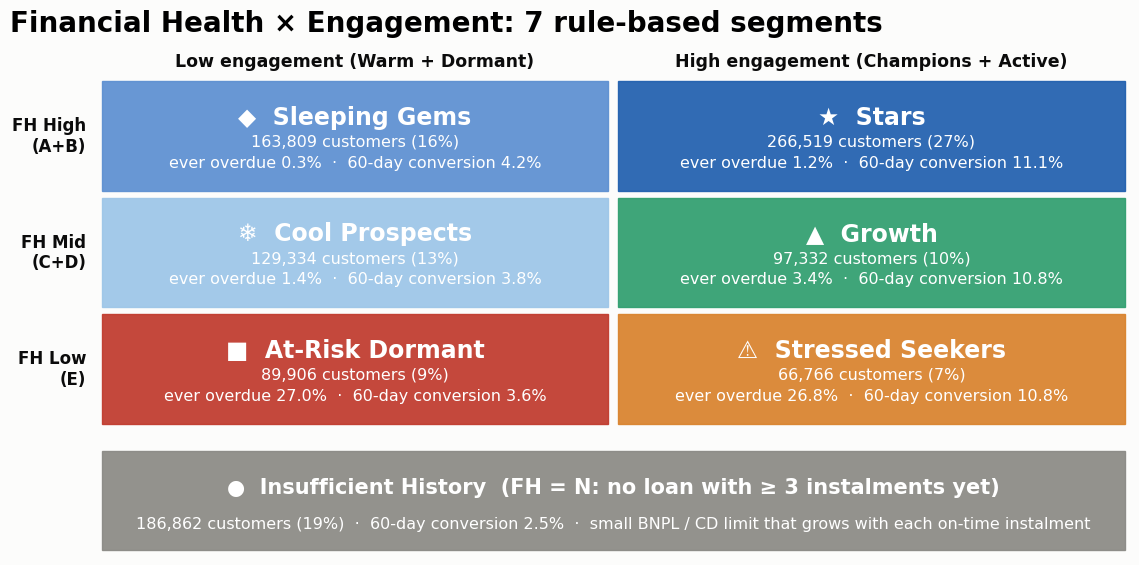

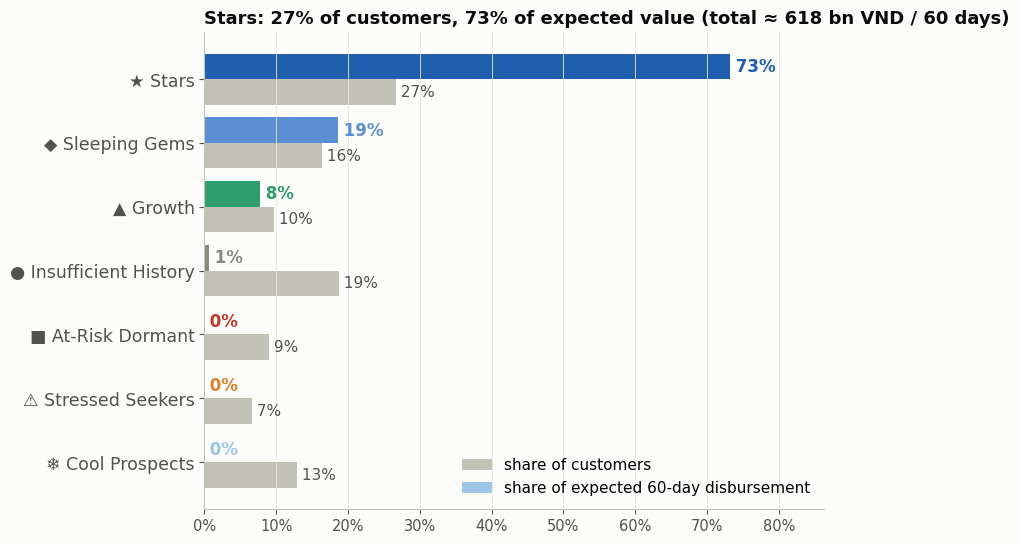

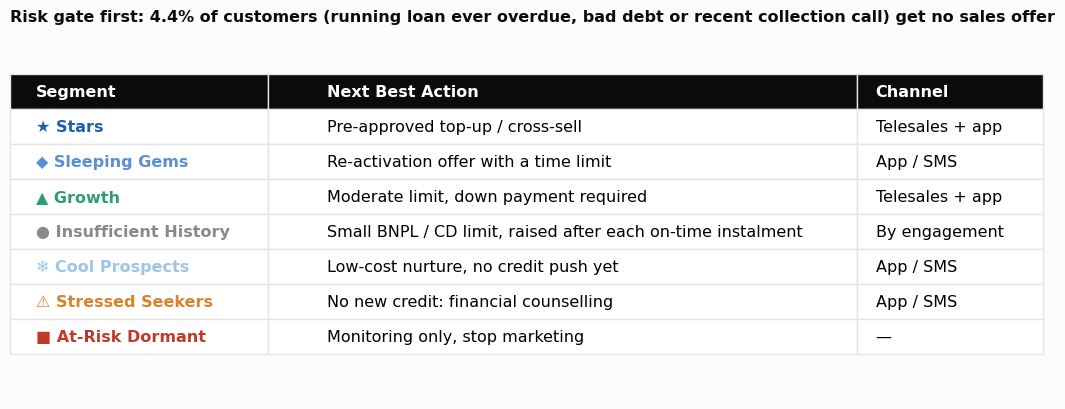

In [15]:
SLIDE = {"figsize": (13.33, 6.2), "dpi": 200}
CELLS = [("High", "Low"), ("High", "High"), ("Mid", "Low"), ("Mid", "High"), ("Low", "Low"), ("Low", "High")]
ICON = {"Stars": "★", "Sleeping Gems": "◆", "Growth": "▲", "Cool Prospects": "❄", "Stressed Seekers": "⚠", "At-Risk Dormant": "■",
        SEG_ORDER[-1]: "●"}
SEG_FILL = {"Stars": "#1f5fae", "Sleeping Gems": "#5b8fd1", "Growth": "#2f9e6e", "Cool Prospects": "#9cc5e8",
            "Stressed Seekers": "#d9822b", "At-Risk Dormant": "#c0392b", SEG_ORDER[-1]: "#8a8984"}

# --- Slide 1: segment matrix
fig = plt.figure(figsize=SLIDE["figsize"])
gs = fig.add_gridspec(2, 1, height_ratios=[3.2, 1], hspace=0.08)
axm = fig.add_subplot(gs[0])
axm.set_xlim(0, 2); axm.set_ylim(0, 3); axm.axis("off")
for (f, e) in CELLS:
    name = SEG_MAP[(f, e)]
    r = seg.loc[name]
    x, y = (0 if e == "Low" else 1), {"High": 2, "Mid": 1, "Low": 0}[f]
    axm.add_patch(plt.Rectangle((x + 0.01, y + 0.03), 0.98, 0.94, color=SEG_FILL[name], alpha=0.92))
    axm.text(x + 0.5, y + 0.66, f"{ICON[name]}  {name}", ha="center", va="center", fontsize=17, fontweight="bold", color="white")
    axm.text(x + 0.5, y + 0.36, f"{int(r.customers):,} customers ({r.share_customers:.0%})\n"
             f"ever overdue {r.ever_overdue:.1%}  ·  60-day conversion {r.p_conv_60d:.1%}",
             ha="center", va="center", fontsize=11.5, color="white", linespacing=1.5)
for y, axis_label in zip([2.5, 1.5, 0.5], ["FH High\n(A+B)", "FH Mid\n(C+D)", "FH Low\n(E)"]):
    axm.text(-0.02, y, axis_label, ha="right", va="center", fontsize=12, fontweight="bold", color="#0b0b0b")
for x, axis_label in zip([0.5, 1.5], ["Low engagement (Warm + Dormant)", "High engagement (Champions + Active)"]):
    axm.text(x, 3.06, axis_label, ha="center", va="bottom", fontsize=12.5, fontweight="bold", color="#0b0b0b")
axn = fig.add_subplot(gs[1])
r = seg.loc[SEG_ORDER[-1]]
axn.set_xlim(0, 2); axn.set_ylim(0, 1); axn.axis("off")
axn.add_patch(plt.Rectangle((0.01, 0.05), 1.98, 0.9, color=SEG_FILL[SEG_ORDER[-1]], alpha=0.92))
axn.text(1, 0.62, f"{ICON[SEG_ORDER[-1]]}  {SEG_ORDER[-1]}  (FH = N: no loan with ≥ 3 instalments yet)", ha="center", va="center",
         fontsize=15, fontweight="bold", color="white")
axn.text(1, 0.28, f"{int(r.customers):,} customers ({r.share_customers:.0%})  ·  60-day conversion {r.p_conv_60d:.1%}  ·  "
         "small BNPL / CD limit that grows with each on-time instalment", ha="center", va="center", fontsize=11.5, color="white")
fig.suptitle("Financial Health × Engagement: 7 rule-based segments", x=0.06, ha="left", fontsize=20, fontweight="bold", y=0.99)
fig.savefig(FIG / "slide1_segment_matrix.png", dpi=SLIDE["dpi"], bbox_inches="tight", facecolor="white")
plt.show()

# --- Slide 2a: customers vs value
fig, ax = plt.subplots(figsize=(8, 6.2))
order = seg.sort_values("share_value").index
y = np.arange(len(order)); w = 0.4
ax.barh(y - w / 2, seg.loc[order, "share_customers"], w, color="#c3c2b7", label="share of customers")
ax.barh(y + w / 2, seg.loc[order, "share_value"], w, color=[SEG_FILL[s] for s in order], label="share of expected 60-day disbursement")
for i, s in enumerate(order):
    ax.text(seg.loc[s, "share_customers"], i - w / 2, f" {seg.loc[s, 'share_customers']:.0%}", va="center", fontsize=11, color="#52514e")
    ax.text(seg.loc[s, "share_value"], i + w / 2, f" {seg.loc[s, 'share_value']:.0%}", va="center", fontsize=12, fontweight="bold",
            color=SEG_FILL[s])
ax.set_yticks(y, [f"{ICON[s]} {s}" for s in order], fontsize=12.5)
ax.xaxis.set_major_formatter(PCT); ax.set_xlim(0, seg["share_value"].max() * 1.18); ax.grid(axis="y", visible=False)
ax.tick_params(axis="x", labelsize=10.5)
ax.legend(frameon=False, loc="lower right", fontsize=11)
top = seg["share_value"].idxmax()
ax.set_title(f"{top}: {seg.loc[top, 'share_customers']:.0%} of customers, {seg.loc[top, 'share_value']:.0%} of expected value "
             f"(total ≈ {seg['expected_disbursement_bn'].sum():,.0f} bn VND / 60 days)", loc="left", fontsize=13, fontweight="bold")
fig.savefig(FIG / "slide2_customers_vs_value.png", dpi=SLIDE["dpi"], bbox_inches="tight", facecolor="white")
plt.show()

# --- Slide 2b: NBA table
nba_rows = [("Stars", "Pre-approved top-up / cross-sell", "Telesales + app"),
            ("Sleeping Gems", "Re-activation offer with a time limit", "App / SMS"),
            ("Growth", "Moderate limit, down payment required", "Telesales + app"),
            (SEG_ORDER[-1], "Small BNPL / CD limit, raised after each on-time instalment", "By engagement"),
            ("Cool Prospects", "Low-cost nurture, no credit push yet", "App / SMS"),
            ("Stressed Seekers", "No new credit: financial counselling", "App / SMS"),
            ("At-Risk Dormant", "Monitoring only, stop marketing", "—")]
blocked_share = (df["rule"] == "R1 risk block").mean()
fig, ax = plt.subplots(figsize=(13.33, 4.8))
ax.axis("off")
tbl = ax.table(cellText=[[f"{ICON[s]} {s}", a, c] for s, a, c in nba_rows], colLabels=["Segment", "Next Best Action", "Channel"],
               colWidths=[0.25, 0.57, 0.18], loc="center", cellLoc="left", colLoc="left")
tbl.auto_set_font_size(False); tbl.set_fontsize(11.5); tbl.scale(1, 2.1)
for (i, j), cell in tbl.get_celld().items():
    cell.set_edgecolor("#e6e5e0")
    if i == 0:
        cell.set_facecolor("#0b0b0b"); cell.set_text_props(color="white", fontweight="bold")
    elif j == 0:
        cell.set_text_props(color=SEG_FILL[nba_rows[i - 1][0]], fontweight="bold")
ax.set_title(f"Risk gate first: {blocked_share:.1%} of customers (running loan ever overdue, bad debt or recent collection call) get no sales offer",
             loc="left", fontsize=11.5, fontweight="bold")
fig.savefig(FIG / "slide2_nba_table.png", dpi=SLIDE["dpi"], bbox_inches="tight", facecolor="white")
plt.show()

---
## 7. Kết luận và xuất file

In [16]:
export_cols = ["SKP_CLIENT", "FH_score", "FH_segment", "ENG_score", "ENG_segment", "Segment", "NBA_action", "NBA_product",
               "NBA_channel", "NBA_timing", "expected_disbursement", "expected_loss", "NBA_why", "AB_group"]
nba = df[export_cols].copy()
nba[["expected_disbursement", "expected_loss"]] = nba[["expected_disbursement", "expected_loss"]].round(0)
nba.to_csv(OUT / "customer_nba.csv", index=False, encoding="utf-8-sig")
nulls = nba[["Segment", "NBA_action", "NBA_why"]].isna().sum()
assert len(nba) == len(lab) and nba["SKP_CLIENT"].is_unique and nulls.sum() == 0, (nulls.to_dict(),
    nba.loc[nba[["Segment", "NBA_action", "NBA_why"]].isna().any(axis=1), ["Segment", "NBA_action"]].value_counts(dropna=False).head())
print(f"customer_nba.csv: {len(nba):,} rows -> {OUT}")

# Add the Challenge 3 segment to the submission file (labels only; helper variables stay inside this notebook)
full = pd.read_parquet(LABEL_FILE) if LABEL_FILE.suffix == ".parquet" else pd.read_csv(LABEL_FILE)
full = full.drop(columns=[c for c in ["Segment"] if c in full]).merge(df[["SKP_CLIENT", "Segment"]], on="SKP_CLIENT",
                                                                       how="left", validate="one_to_one")
assert len(full) == len(lab) and full["Segment"].notna().all()
full.to_parquet(OUT / "CUSTOMER_clean_labeled.parquet", index=False)
full.to_csv(OUT / "CUSTOMER_clean_labeled.csv", index=False, encoding="utf-8-sig")
print(f"CUSTOMER_clean_labeled: {full.shape[1]} columns, last 5 = {list(full.columns[-5:])}")
print("Files:", sorted(p.name for p in OUT.glob("*.csv")))
nba.sample(5, random_state=1)

customer_nba.csv: 1,000,528 rows -> C:\Users\huynh\AppData\Local\Temp\claude\d--Thi-BI10-ROUND02-DATASET\4bfc395d-6f4b-42a6-9693-c978ca8489f7\scratchpad\BI10_ROOT\output\challenge3


CUSTOMER_clean_labeled: 20 columns, last 5 = ['financial_health_score', 'FH_segment', 'ENG_score', 'ENG_segment', 'Segment']
Files: ['CUSTOMER_clean_labeled.csv', 'ab_test_plan.csv', 'customer_nba.csv', 'segment_summary.csv']


,SKP_CLIENT,FH_score,FH_segment,ENG_score,ENG_segment,Segment,NBA_action,NBA_product,NBA_channel,NBA_timing,expected_disbursement,expected_loss,NBA_why,AB_group
664327,76838417,53.7000,C · Trung bình,54.9000,Warm,Cool Prospects,"Low-cost nurture: content and app onboarding, no credit push",None,App / SMS,n/a,0.0000,0.0000,FH 54 (C · Trung bình) × ENG 55 (Warm) → Cool Prospects. moderate health and low interest: keep warm cheaply until a need signal appears.,treatment
791151,125797104,72.5000,A · Rất khỏe,46.9000,Warm,Sleeping Gems,Re-activation: pre-approved offer with a time limit,TW,App push / SMS,Now,"1,193,566.0000","8,759.0000",FH 72 (A · Rất khỏe) × ENG 47 (Warm) → Sleeping Gems. healthy but drifting away: a cheap digital nudge before they leave. Product TW: recent lead for TW. Channel: App push / SMS.,treatment
254703,124186439,0.0000,E · Rủi ro cao,63.6000,Active,Stressed Seekers,"Repayment support: no sales, reminder and restructuring advice",None,Collection-care team / SMS,n/a,0.0000,0.0000,FH 0 (E · Rủi ro cao) × ENG 64 (Active) → Stressed Seekers. Blocked: a running loan has been overdue.,treatment
173065,22415360,49.2000,D · Yếu,92.6000,Champions,Growth,"Right-sized offer with down payment, moderate limit",CD,Telesales + app,Now,"895,688.0000","26,704.0000",FH 49 (D · Yếu) × ENG 93 (Champions) → Growth. interested but only moderately healthy: grow carefully with limits matched to capacity. Product CD: repeat CD. Channel: Telesales + app.,treatment
645576,11324533,58.1000,B · Khỏe,63.6000,Active,Stars,Pre-approved top-up / cross-sell offer,CL,Telesales + app,Now – loan ending: renewal,"2,197,656.0000","26,040.0000",FH 58 (B · Khỏe) × ENG 64 (Active) → Stars. healthy and actively engaging: highest expected conversion at the lowest risk. Product CL: does not hold CL yet. Now: a loan ends within 60 days (customers with an ended loan return ×2 more often). Channel: Teles...,treatment


### Trả lời 4 yêu cầu của Challenge 3
| # | Yêu cầu | Trả lời | Bằng chứng |
|---|---|---|---|
| 1 | Combine FH and Engagement | Phân khúc **theo quy tắc**: ma trận FH (Cao / Trung bình / Thấp) × ENG (Cao / Thấp) + nhóm *Chưa đủ lịch sử trả nợ* → **7 phân khúc** | Hai điểm tương quan vừa (ρ = 0,49), nên bổ sung cho nhau; ngưỡng dùng lại từ Challenge 1 và 2 |
| 2 | Customer Opportunities | Giải ngân kỳ vọng 60 ngày khoảng **618 tỷ VND**; Stars = 27% khách nhưng **73% giá trị**; Stars + Sleeping Gems ≈ 92% | Chuyển đổi out-of-time của Challenge 2 × số tiền giải ngân thực năm 2025 |
| 3 | Next Best Action | 4 quy tắc theo thứ tự ưu tiên; mỗi khách có hành động, sản phẩm, kênh, thời điểm | 4,4% bị chặn rủi ro; 31% khách được chào bán nhận "chào vay tiếp" đúng lúc khoản vay kết thúc |
| 4 | Why this action? | Câu giải thích cho từng khách (`NBA_why`) + số liệu bằng chứng cho từng phân khúc + kế hoạch A/B test | Stressed Seekers: phản hồi bán hàng cao nhất (6,3%) nhưng 27% từng quá hạn → chặn |

### Khuyến nghị
1. **Ưu tiên Stars** (telesales + app, ưu đãi duyệt sẵn), chú ý **thời điểm**: chào vay tiếp khi khoản vay sắp kết thúc, không chào ngay sau giải ngân.
2. **Kích hoạt Sleeping Gems bằng kênh số**: nhóm có rủi ro thấp nhất (0,3% từng quá hạn), mang 19% giá trị.
3. **Không cấp thêm tín dụng cho Stressed Seekers**: chuyển sang tư vấn tài chính và nhắc trả nợ.
4. **Xây lịch sử trả nợ cho nhóm Insufficient History**: hạn mức nhỏ (BNPL/CD), tăng dần sau mỗi kỳ trả đúng hạn. Thiếu bằng chứng trả nợ thì chưa xếp vào nhóm khỏe.
5. **Triển khai qua A/B test** với nhóm đối chứng 10%, theo dõi chỉ số an toàn về quá hạn.

### Hạn chế
- Chuyển đổi lấy theo phân khúc ENG, chưa kiểm chứng riêng cho từng ô FH × ENG, vì FH chỉ chấm tại ngày chốt.
- "Đang quá hạn" được xấp xỉ bằng *khoản vay đang chạy từng quá hạn ở 4 kỳ đầu*, vì không có trạng thái nợ hiện tại.
- Giá trị là số tiền giải ngân, chưa trừ chi phí vốn và chi phí kênh.
- Chưa có dữ liệu phản hồi SMS/app, nên hiệu quả kênh số phải đo bằng A/B test. Dữ liệu CALL sau ngày chốt cần BTC xác nhận.